Introduction
Flight ticket prices can vary depending on several factors, including the airline, journey date, departure time, arrival time, flight duration, route and number of stops.
The objective of this project is to analyse flight fare data and develop machine learning models that can predict flight ticket prices based on the available flight information.
The project involves cleaning and understanding the dataset, performing exploratory data analysis, engineering useful features and developing regression models.
Three machine learning algorithms are used for prediction:
    Linear Regression
    Random Forest Regressor
    XGBoost Regressor
Their performance is evaluated using appropriate regression metrics to identify the best-performing model for flight price prediction.

Project Objectives
Understand and analyse the flight price dataset.
Clean missing values and duplicate records.
Perform exploratory data analysis to identify useful patterns and relationships.
Prepare the dataset through feature engineering and preprocessing.
Develop multiple regression models to predict flight prices.
Compare model performance and recommend the most suitable model.

Importing Libraries

The required Python libraries are imported to perform data manipulation, numerical calculations, data visualisation and machine learning.

- **Pandas:** Used for loading, manipulating and analysing the dataset.
- **NumPy:** Used for numerical operations and calculations.
- **Matplotlib:** Used for creating graphs and visualisations.
- **Seaborn:** Used for statistical data visualisation.

In [1]:
#importing lib
import pandas as pd  #used for loading dataset
import numpy as np  # for numerical operation and calculation
import matplotlib.pyplot as plt  #for graphs and visuals
import seaborn as sns  #for statistical visualization

Loading and Understanding the Dataset
The flight fare dataset is loaded into a Pandas DataFrame for further analysis. Initial inspection is performed to understand the structure, size, columns, data types and statistical properties of the dataset.
Dataset Overview:
The original dataset contains 10,683 records and 11 columns. It includes information about airlines, journey dates, source and destination locations, routes, departure and arrival times, flight duration, number of stops, additional information and flight prices.
The target variable for this project is **Price**, while the remaining columns provide information that can be used to predict flight prices.

In [2]:
#Loading the excel data into df
df=pd.read_excel("Flight_Fare.xlsx")

The `head()` method is used to display the first five records of the dataset. This helps us understand how the data is organised and what values each column contains.

In [3]:
#display first 5 rows of the dataset
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


The `shape` attribute is used to identify the total number of rows and columns in the dataset. This provides an overview of the dataset size.

In [4]:
#To check the number of rows and cols (rows,cols)
df.shape

(10683, 11)

In [5]:
#To only display the cols name
df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price'],
      dtype='object')

The `info()` method provides information about column names,data types and non-null record counts. 
It helps identify columns that may require data type conversion.

In [6]:
# To display the info about the dataset(colname, no.of non-null,datatype)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


The `describe()` method provides statistical information about numerical columns, including count, mean, standard deviation, minimum, maximum and quartile values.

In [7]:
# To know the statistical info for numerical col
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


The `isnull().sum()` operation identifies the number of missing values in each column. 
This helps determine whether data cleaning is required.

In [8]:
# To check the number of missing values in each col
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

## 4. Data Cleaning and Preprocessing
Data cleaning and preprocessing are important steps in preparing the dataset for machine learning. The original dataset contains missing values, duplicate records and columns stored in text formats that need to be converted into useful numerical features.

The following steps are performed to clean and prepare the dataset:

- Handling missing values.
- Removing duplicate records.
- Converting journey dates into numerical features.
- Extracting departure and arrival time components.
- Converting flight duration into minutes.
- Converting the number of stops into numerical values.
- Cleaning categorical text values.

Handling Missing Values:
The missing-value check identified one record containing missing values in both the Route and Total_Stops columns.
Since the missing information could not be reliably recovered, the incomplete record was removed using the dropna() method.
After this operation, the dataset contained 10,682 records.

In [9]:
# removing rows which has missing values
#dropna - romoves the row which has missing val
#inplace=True- applies the same to exisiting dataframe
df.dropna(inplace=True) 

In [10]:
# To verify whetehr the changes have applied
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

In [11]:
# Check the rows and cols of updated df
df.shape

(10682, 11)

Removing Duplicate Records:
Duplicate records were identified using the duplicated() method.
A total of 220 duplicate records were found and removed using drop_duplicates().
Removing duplicate records helps prevent repeated observations from unnecessarily influencing the analysis and model training.
After removing duplicates, the dataset contained 10,462 records.

In [12]:
#checking the number of duplicated rows
df.duplicated().sum()

np.int64(220)

In [13]:
# Displaying the duplicate rows
df[df.duplicated(keep=False)].head(10)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
33,Jet Airways,15/06/2019,Delhi,Cochin,DEL → NAG → BOM → COK,14:35,12:35 16 Jun,22h,2 stops,In-flight meal not included,10919
49,Jet Airways,27/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,19:00 28 Jun,19h 55m,2 stops,In-flight meal not included,11150
73,Jet Airways,24/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,12:35 25 Jun,13h 30m,2 stops,No info,12819
81,Jet Airways,24/03/2019,Banglore,New Delhi,BLR → DEL,19:55,22:35,2h 40m,non-stop,No info,7229
87,Jet Airways,6/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,09:40,04:25 07 Jun,18h 45m,2 stops,No info,13014
136,Jet Airways,6/06/2019,Delhi,Cochin,DEL → NAG → BOM → COK,06:45,04:25 07 Jun,21h 40m,2 stops,No info,13376
137,Air India,27/06/2019,Delhi,Cochin,DEL → GOI → BOM → COK,22:00,19:15 28 Jun,21h 15m,2 stops,No info,10441
209,Jet Airways,18/05/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,04:25 20 May,29h 20m,2 stops,No info,15129
224,Jet Airways,9/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,05:30,04:25 10 Jun,22h 55m,2 stops,No info,13014
251,Air India,1/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,19:45,19:15 02 Jun,23h 30m,2 stops,No info,10651


In [14]:
df.shape

(10682, 11)

In [15]:
df[df.duplicated(keep=False)].sort_values(
    by=list(df.columns)
)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
6321,Air India,01/03/2019,Banglore,New Delhi,BLR → BOM → AMD → DEL,08:50,23:55 02 Mar,39h 5m,2 stops,No info,17135
9848,Air India,01/03/2019,Banglore,New Delhi,BLR → BOM → AMD → DEL,08:50,23:55 02 Mar,39h 5m,2 stops,No info,17135
572,Air India,03/03/2019,Banglore,New Delhi,BLR → DEL,21:10,23:55,2h 45m,non-stop,No info,7591
8168,Air India,03/03/2019,Banglore,New Delhi,BLR → DEL,21:10,23:55,2h 45m,non-stop,No info,7591
1495,Air India,1/04/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,01:20 02 Apr,15h 20m,2 stops,No info,10408
...,...,...,...,...,...,...,...,...,...,...,...
2870,SpiceJet,24/03/2019,Banglore,New Delhi,BLR → DEL,05:45,08:35,2h 50m,non-stop,No check-in baggage included,4273
1535,SpiceJet,24/03/2019,Banglore,New Delhi,BLR → DEL,20:30,23:20,2h 50m,non-stop,No check-in baggage included,3873
3711,SpiceJet,24/03/2019,Banglore,New Delhi,BLR → DEL,20:30,23:20,2h 50m,non-stop,No check-in baggage included,3873
2634,Vistara,24/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,5403


In [16]:
# To remove the duplicates from the df
df.drop_duplicates(inplace=True)

In [17]:
df.shape

(10462, 11)

In [18]:
# to check the dtype of each col
df.dtypes

Airline            object
Date_of_Journey    object
Source             object
Destination        object
Route              object
Dep_Time           object
Arrival_Time       object
Duration           object
Total_Stops        object
Additional_Info    object
Price               int64
dtype: object

In [19]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


Date Feature Extraction:
The Date_of_Journey column was initially stored as text. It was converted into datetime format using Pandas.
The journey day, month and year were extracted into separate columns named Journey_Day, Journey_Month and Journey_Year.
The original date column was removed after extracting these components because the required date information was available in the new columns.

In [20]:
# display the first 10 journey dates
df["Date_of_Journey"].head(10)

0    24/03/2019
1     1/05/2019
2     9/06/2019
3    12/05/2019
4    01/03/2019
5    24/06/2019
6    12/03/2019
7    01/03/2019
8    12/03/2019
9    27/05/2019
Name: Date_of_Journey, dtype: object

In [21]:
# Convert date_of_journey from string format into datetime format
df['Date_of_Journey'] = pd.to_datetime(
    df['Date_of_Journey'],
    dayfirst=True
)

In [22]:
#Display the first 10 converted dates
df['Date_of_Journey'].head(10)

0   2019-03-24
1   2019-05-01
2   2019-06-09
3   2019-05-12
4   2019-03-01
5   2019-06-24
6   2019-03-12
7   2019-03-01
8   2019-03-12
9   2019-05-27
Name: Date_of_Journey, dtype: datetime64[ns]

In [23]:
df.dtypes

Airline                    object
Date_of_Journey    datetime64[ns]
Source                     object
Destination                object
Route                      object
Dep_Time                   object
Arrival_Time               object
Duration                   object
Total_Stops                object
Additional_Info            object
Price                       int64
dtype: object

In [24]:
# extract the day from the journey date
#.dt allows us to acces indivdual components from datetime col
df['Journey_Day']=df['Date_of_Journey'].dt.day
# extract the month from the journey date
df['Journey_Month']=df['Date_of_Journey'].dt.month
# extract the year from the journey date
df['Journey_Year']=df['Date_of_Journey'].dt.year

In [25]:
# Display the newly cretaed cols
df[['Date_of_Journey','Journey_Day','Journey_Month','Journey_Year']].head(10)

,Date_of_Journey,Journey_Day,Journey_Month,Journey_Year
0,2019-03-24,24,3,2019
1,2019-05-01,1,5,2019
2,2019-06-09,9,6,2019
3,2019-05-12,12,5,2019
4,2019-03-01,1,3,2019
5,2019-06-24,24,6,2019
6,2019-03-12,12,3,2019
7,2019-03-01,1,3,2019
8,2019-03-12,12,3,2019
9,2019-05-27,27,5,2019


In [26]:
# Display the data types of the newly created columns
df[['Journey_Day', 'Journey_Month', 'Journey_Year']].dtypes

Journey_Day      int32
Journey_Month    int32
Journey_Year     int32
dtype: object

In [27]:
# Remove the Date_of_Journey as we have extracted the needed data
df.drop('Date_of_Journey',axis=1,inplace=True) #axis=1 mentions the col, axis=0 means row

Departure Time Extraction:
The Dep_Time column was converted into datetime format.
The hour and minute components were extracted into two separate numerical features:
     Dep_Hour
     Dep_Minute
The original departure time column was removed after extraction.

In [28]:
#display the departures time
df['Dep_Time'].head(10)

0    22:20
1    05:50
2    09:25
3    18:05
4    16:50
5    09:00
6    18:55
7    08:00
8    08:55
9    11:25
Name: Dep_Time, dtype: object

In [29]:
# Convert departure time using the specified format
dep_time = pd.to_datetime(df['Dep_Time'], format='%H:%M')

# Extract departure hour
df['Dep_Hour'] = dep_time.dt.hour

# Extract departure minute
df['Dep_Minute'] = dep_time.dt.minute

# Display the results
df[['Dep_Time', 'Dep_Hour', 'Dep_Minute']].head(10)

,Dep_Time,Dep_Hour,Dep_Minute
0,22:20,22,20
1,05:50,5,50
2,09:25,9,25
3,18:05,18,5
4,16:50,16,50
5,09:00,9,0
6,18:55,18,55
7,08:00,8,0
8,08:55,8,55
9,11:25,11,25


In [30]:
#Delete the dep_time col
df.drop('Dep_Time',axis=1,inplace=True)

In [31]:
df.head()

,Airline,Source,Destination,Route,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019,22,20
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,13:15,7h 25m,2 stops,No info,7662,1,5,2019,5,50
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019,9,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,23:30,5h 25m,1 stop,No info,6218,12,5,2019,18,5
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,21:35,4h 45m,1 stop,No info,13302,1,3,2019,16,50


Arrival Time Extraction:
Some values in the Arrival_Time column contained both time and date information.
The time portion was extracted and converted into datetime format. The arrival hour and minute were then stored in separate numerical columns:
Arrival_Hour
Arrival_Minute
The original arrival time column was removed after extraction.

In [32]:
#display the arrival time
df['Arrival_Time'].head(10)

0    01:10 22 Mar
1           13:15
2    04:25 10 Jun
3           23:30
4           21:35
5           11:25
6    10:25 13 Mar
7    05:05 02 Mar
8    10:25 13 Mar
9           19:15
Name: Arrival_Time, dtype: object

In [33]:
# some arrival has date with it so we split it
# str.split() - split wherever it find space
# str[0]- select the first part
arrival_time=df['Arrival_Time'].str.split().str[0]

In [34]:
# we have split the time to arrival_time
arrival_time.head(10)

0    01:10
1    13:15
2    04:25
3    23:30
4    21:35
5    11:25
6    10:25
7    05:05
8    10:25
9    19:15
Name: Arrival_Time, dtype: object

In [35]:
#convert the extracted arrival time to datetime format
arrival_datetime=pd.to_datetime(arrival_time,format='%H:%M')
#Extract arrival hour
df['Arrival_Hour']=arrival_datetime.dt.hour
#Extract arrival minute
df['Arrival_Minute']=arrival_datetime.dt.minute

In [36]:
#display the result
df[['Arrival_Time','Arrival_Hour','Arrival_Minute']].head(10)

,Arrival_Time,Arrival_Hour,Arrival_Minute
0,01:10 22 Mar,1,10
1,13:15,13,15
2,04:25 10 Jun,4,25
3,23:30,23,30
4,21:35,21,35
5,11:25,11,25
6,10:25 13 Mar,10,25
7,05:05 02 Mar,5,5
8,10:25 13 Mar,10,25
9,19:15,19,15


In [37]:
# Remove the extra data
df.drop('Arrival_Time',axis=1,inplace=True)
df.head()

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,2h 50m,non-stop,No info,3897,24,3,2019,22,20,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,7h 25m,2 stops,No info,7662,1,5,2019,5,50,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,19h,2 stops,No info,13882,9,6,2019,9,25,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,5h 25m,1 stop,No info,6218,12,5,2019,18,5,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,4h 45m,1 stop,No info,13302,1,3,2019,16,50,21,35


Flight Duration Conversion:
The Duration column contained flight durations in different text formats, such as hours and minutes. Some records contained only minutes.
The duration was separated into hours and minutes. Missing hour values were filled with zero for records containing only minutes.
A new feature, Duration_Total_Minutes, was created by converting the entire flight duration into minutes.
The original duration column and temporary extraction columns were removed after the conversion.

In [38]:
# Display the first 10 flight durations
df['Duration'].head(10)

0     2h 50m
1     7h 25m
2        19h
3     5h 25m
4     4h 45m
5     2h 25m
6    15h 30m
7     21h 5m
8    25h 30m
9     7h 50m
Name: Duration, dtype: object

In [39]:
# Find duration values where hours could not be extracted
# .str.extract(r'(\d+)h') tries to extract hours.
# .isna() identifies values where extraction failed.
df[df['Duration'].str.extract(r'(\d+)h').isna()[0]]['Duration'].value_counts()

Duration
5m    1
Name: count, dtype: int64

In [40]:
# Extract hours from the Duration column
df['Duration_Hours'] = (
    df['Duration'].str.extract(r'(\d+)h')[0].fillna(0).astype(int)
)

# Display the original duration and extracted hours
df[['Duration', 'Duration_Hours']].head(10)

,Duration,Duration_Hours
0,2h 50m,2
1,7h 25m,7
2,19h,19
3,5h 25m,5
4,4h 45m,4
5,2h 25m,2
6,15h 30m,15
7,21h 5m,21
8,25h 30m,25
9,7h 50m,7


In [41]:
# Extract minutes from the Duration column
df['Duration_Minutes'] = (
    df['Duration'].str.extract(r'(\d+)m')[0].fillna(0).astype(int)
)

# Display the original duration and extracted minutes
df[['Duration', 'Duration_Hours', 'Duration_Minutes']].head(10)

,Duration,Duration_Hours,Duration_Minutes
0,2h 50m,2,50
1,7h 25m,7,25
2,19h,19,0
3,5h 25m,5,25
4,4h 45m,4,45
5,2h 25m,2,25
6,15h 30m,15,30
7,21h 5m,21,5
8,25h 30m,25,30
9,7h 50m,7,50


In [42]:
# Converts hours into minutes and add remaining mins
df['Duration_Total_Minutes']=(
    df['Duration_Hours'] * 60 + df['Duration_Minutes']
)

# Dislay all the Durations
df[['Duration', 'Duration_Hours', 'Duration_Minutes',
    'Duration_Total_Minutes']].head(10)

,Duration,Duration_Hours,Duration_Minutes,Duration_Total_Minutes
0,2h 50m,2,50,170
1,7h 25m,7,25,445
2,19h,19,0,1140
3,5h 25m,5,25,325
4,4h 45m,4,45,285
5,2h 25m,2,25,145
6,15h 30m,15,30,930
7,21h 5m,21,5,1265
8,25h 30m,25,30,1530
9,7h 50m,7,50,470


In [43]:
# Remove the cols which are not needed
df.drop(['Duration','Duration_Hours','Duration_Minutes'],
       axis=1,
       inplace=True)

In [44]:
df.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Total_Minutes
0,IndiGo,Banglore,New Delhi,BLR → DEL,non-stop,No info,3897,24,3,2019,22,20,1,10,170
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2 stops,No info,7662,1,5,2019,5,50,13,15,445
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2 stops,No info,13882,9,6,2019,9,25,4,25,1140
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1 stop,No info,6218,12,5,2019,18,5,23,30,325
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1 stop,No info,13302,1,3,2019,16,50,21,35,285


Converting Total Stops:
The `Total_Stops` column originally contained categorical values such as `non-stop`, `1 stop`, `2 stops`, and so on.
These values were mapped to numerical representations:
- Non-stop = 0
- 1 stop = 1
- 2 stops = 2
- 3 stops = 3
- 4 stops = 4
This conversion makes the number of stops available as a numerical feature.

In [45]:
# Display the different values and its count
df['Total_Stops'].value_counts()

Total_Stops
1 stop      5625
non-stop    3475
2 stops     1318
3 stops       43
4 stops        1
Name: count, dtype: int64

In [46]:
# CReate a dict tomap text values to num
stops_mapping={
    'non-stop':0,
    '1 stop':1,
    '2 stops':2,
    '3 stops':3,
    '4 stops':4
}

#Replace the text val to corresponding number
df['Total_Stops']=df['Total_Stops'].map(stops_mapping)

#display the val
df[['Total_Stops']].head(10)

,Total_Stops
0,0
1,2
2,2
3,1
4,1
5,0
6,1
7,1
8,1
9,1


In [47]:
df.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Total_Minutes
0,IndiGo,Banglore,New Delhi,BLR → DEL,0,No info,3897,24,3,2019,22,20,1,10,170
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2,No info,7662,1,5,2019,5,50,13,15,445
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2,No info,13882,9,6,2019,9,25,4,25,1140
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1,No info,6218,12,5,2019,18,5,23,30,325
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1,No info,13302,1,3,2019,16,50,21,35,285


In [48]:
df['Route'].head(10)

0                BLR → DEL
1    CCU → IXR → BBI → BLR
2    DEL → LKO → BOM → COK
3          CCU → NAG → BLR
4          BLR → NAG → DEL
5                CCU → BLR
6          BLR → BOM → DEL
7          BLR → BOM → DEL
8          BLR → BOM → DEL
9          DEL → BOM → COK
Name: Route, dtype: object

Cleaning Categorical Text Values:
The Additional_Info column contained text categories with possible unnecessary spaces and inconsistent letter casing.
The str.strip() and str.lower() methods were applied to remove extra spaces and convert the text to lowercase.
This helps maintain consistency in categorical values.

In [49]:
# Count how many times each category appears in Additional_Info
df['Additional_Info'].value_counts()

Additional_Info
No info                         8182
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

In [50]:
# Remove unnecessary spaces and convert all text to lowercase
df['Additional_Info'] = df['Additional_Info'].str.strip().str.lower()

# Check the updated categories and their counts
df['Additional_Info'].value_counts()

Additional_Info
no info                         8185
in-flight meal not included     1926
no check-in baggage included     318
1 long layover                    19
change airports                    7
business class                     4
1 short layover                    1
red-eye flight                     1
2 long layover                     1
Name: count, dtype: int64

In [51]:
# Display the unique airline names and their frequencies
df['Airline'].value_counts()

Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

In [52]:
# Display the number of flights from each source city
df['Source'].value_counts()

Source
Delhi       4345
Kolkata     2860
Banglore    2179
Mumbai       697
Chennai      381
Name: count, dtype: int64

In [53]:
# Count the number of flights going to each destination city
df['Destination'].value_counts()

Destination
Cochin       4345
Banglore     2860
Delhi        1265
New Delhi     914
Hyderabad     697
Kolkata       381
Name: count, dtype: int64

In [54]:
df.dtypes

Airline                   object
Source                    object
Destination               object
Route                     object
Total_Stops                int64
Additional_Info           object
Price                      int64
Journey_Day                int32
Journey_Month              int32
Journey_Year               int32
Dep_Hour                   int32
Dep_Minute                 int32
Arrival_Hour               int32
Arrival_Minute             int32
Duration_Total_Minutes     int64
dtype: object

In [55]:
df.isnull().sum()

Airline                   0
Source                    0
Destination               0
Route                     0
Total_Stops               0
Additional_Info           0
Price                     0
Journey_Day               0
Journey_Month             0
Journey_Year              0
Dep_Hour                  0
Dep_Minute                0
Arrival_Hour              0
Arrival_Minute            0
Duration_Total_Minutes    0
dtype: int64

Exploratory Data Analysis (EDA):
Exploratory Data Analysis is performed to understand the distribution of flight prices and identify patterns and relationships between different features.
The analysis is divided into three main parts:
Univariate Analysis: Examines individual variables to understand their distributions and characteristics.
Bivariate Analysis: Examines the relationship between two variables, particularly how individual flight features relate to price.
Multivariate Analysis: Examines relationships between multiple features to identify combined patterns that may influence flight prices.
Visualisations such as histograms, boxplots, count plots, bar charts and scatter plots are used to support the analysis.

Univariate Analysis:
Univariate analysis is used to examine one variable at a time.
It helps understand the distribution, frequency and statistical characteristics of individual features.

The analysis includes flight price distribution, airline frequency, source and destination distribution, 
additional flight information, routes, number of stops, journey dates and flight duration.

Flight Price Distribution:
The statistical summary, histogram and boxplot are used to understand the distribution of flight prices.
The mean flight price is approximately ₹9,026.79, while the median is ₹8,266.
The mean being higher than the median indicates a right-skewed distribution, where some higher-priced flights pull the average upward.
The minimum price is ₹1,759 and the maximum price is ₹79,512. 
The standard deviation is approximately ₹4,624.85, indicating considerable variation in flight prices.

In [56]:
# Univariate analysis - studying 1 col at a time
# Display statistical information about flight prices
df['Price'].describe()

count    10462.000000
mean      9026.790289
std       4624.849541
min       1759.000000
25%       5224.000000
50%       8266.000000
75%      12344.750000
max      79512.000000
Name: Price, dtype: float64

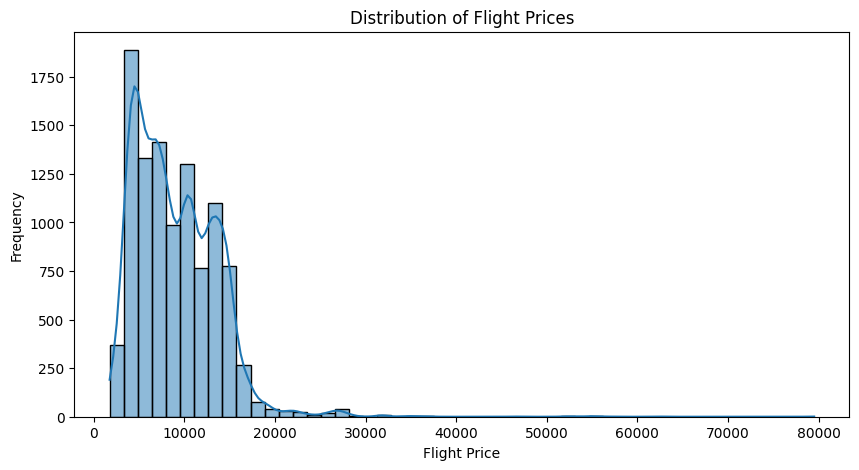

In [57]:
#Histogram
plt.figure(figsize=(10,5))
sns.histplot(df['Price'],bins=50,kde=True)
plt.title("Distribution of Flight Prices")
plt.xlabel("Flight Price")
plt.ylabel("Frequency")
plt.show()

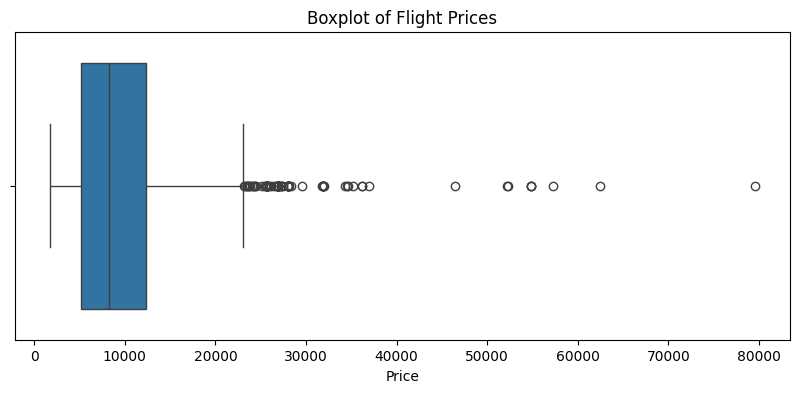

In [58]:
# Boxplot
plt.figure(figsize=(10,4))
sns.boxplot(x=df['Price'])
plt.title("Boxplot of Flight Prices")
plt.show()

Outlier Analysis:
Potential outliers in flight prices were identified using the Interquartile Range (IQR) method.
The first quartile (Q1) is ₹5,224 and the third quartile (Q3) is ₹12,344.75.
The resulting IQR is ₹7,120.75, and the upper outlier boundary is ₹23,025.875.
A total of 94 records, approximately 0.90% of the dataset, were identified as potential high-price outliers.
These records were further examined based on airline information. 
They were retained because high prices may represent premium or business-class flights rather than incorrect data.

In [59]:
#IQR (Interquartile Range) method - to find the outliers
#Calculate first quartile
Q1=df['Price'].quantile(0.25)

# Calculate the third quartile (75th percentile)
Q3 = df['Price'].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Calculate the lower outlier boundary
lower_limit = Q1 - 1.5 * IQR

# Calculate the upper outlier boundary
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 5224.0
Q3: 12344.75
IQR: 7120.75
Lower Limit: -5457.125
Upper Limit: 23025.875


In [60]:
# Count the outliers to know how many flight records fall outside the calculated boundary
# Select prices greater than the upper outlier boundary
outliers = df[df['Price']>upper_limit]

# Count the number of potential outliers
print("Number of potential outliers:", len(outliers))

# Calculate the percentage of potential outliers
print("Percentage of potential outliers:",(len(outliers)/len(df))*100)

Number of potential outliers: 94
Percentage of potential outliers: 0.8984897725100364


In [61]:
# Display the 10 highest flight prices
df.nlargest(10, 'Price')[['Airline', 'Source', 'Destination', 'Total_Stops', 'Additional_Info', 'Price']]

,Airline,Source,Destination,Total_Stops,Additional_Info,Price
2924,Jet Airways Business,Banglore,New Delhi,1,business class,79512
5372,Jet Airways Business,Banglore,New Delhi,1,business class,62427
10364,Jet Airways Business,Banglore,New Delhi,1,business class,57209
1478,Jet Airways,Banglore,New Delhi,1,no info,54826
2618,Jet Airways,Banglore,New Delhi,1,no info,54826
5439,Jet Airways,Banglore,New Delhi,1,no info,54826
9715,Jet Airways Business,Delhi,Cochin,2,no info,52285
657,Jet Airways Business,Banglore,New Delhi,1,no info,52229
7351,Jet Airways Business,Delhi,Cochin,2,no info,46490
396,Multiple carriers,Delhi,Cochin,1,no info,36983


Distribution of Categorical Features:
The distribution of categorical features is examined to understand how frequently different categories occur in the dataset.
The analysis includes:
- **Airline:** Identifies the number of records for each airline.
- **Source:** Shows the distribution of flights based on their departure locations.
- **Destination:** Shows the distribution of flights based on their arrival locations.
- **Additional Information:** Displays the frequency of different types of additional flight information.
- **Route:** Identifies the most frequently occurring flight routes.
- **Total Stops:** Shows how many flights are non-stop or have one or more stops.

Count plots and frequency tables are used to visualise these distributions.

In [62]:
# Count potential outliers for each airline
outliers['Airline'].value_counts()

Airline
Jet Airways             62
Air India               15
Multiple carriers       10
Jet Airways Business     6
SpiceJet                 1
Name: count, dtype: int64

In [63]:
# Count the total flights for each airline
airline_counts = df['Airline'].value_counts()

# Count potential outlier flights for each airline
outlier_counts = outliers['Airline'].value_counts()

# Combine both counts into one DataFrame
outlier_analysis = pd.DataFrame({
    'Total_Flights': airline_counts,
    'Outlier_Flights': outlier_counts
})

# Replace missing outlier counts with zero
outlier_analysis['Outlier_Flights'] = (
    outlier_analysis['Outlier_Flights'].fillna(0)
)

# Calculate the percentage of outliers for each airline
outlier_analysis['Outlier_Percentage'] = (
    outlier_analysis['Outlier_Flights'] /
    outlier_analysis['Total_Flights']
) * 100

# Display airlines in descending order of outlier percentage
outlier_analysis.sort_values(
    by='Outlier_Percentage',
    ascending=False
)

,Total_Flights,Outlier_Flights,Outlier_Percentage
Airline,,,
Jet Airways Business,6,6.0,100.000000
Jet Airways,3700,62.0,1.675676
Air India,1694,15.0,0.885478
Multiple carriers,1196,10.0,0.836120
SpiceJet,815,1.0,0.122699
Air Asia,319,0.0,0.000000
GoAir,194,0.0,0.000000
IndiGo,2043,0.0,0.000000
Multiple carriers Premium economy,13,0.0,0.000000


Airline Distribution:
The airline distribution shows how frequently each airline appears in the dataset.
Jet Airways has the highest number of records, with 3,700 flights, followed by IndiGo with 2,043 flights and Air India with 1,694 flights.
Trujet has only one record, indicating that the dataset contains an uneven distribution of airline categories.
This analysis helps identify which airlines are most represented in the dataset.

In [64]:
# Count how many flights belong to each airline
df['Airline'].value_counts()

Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

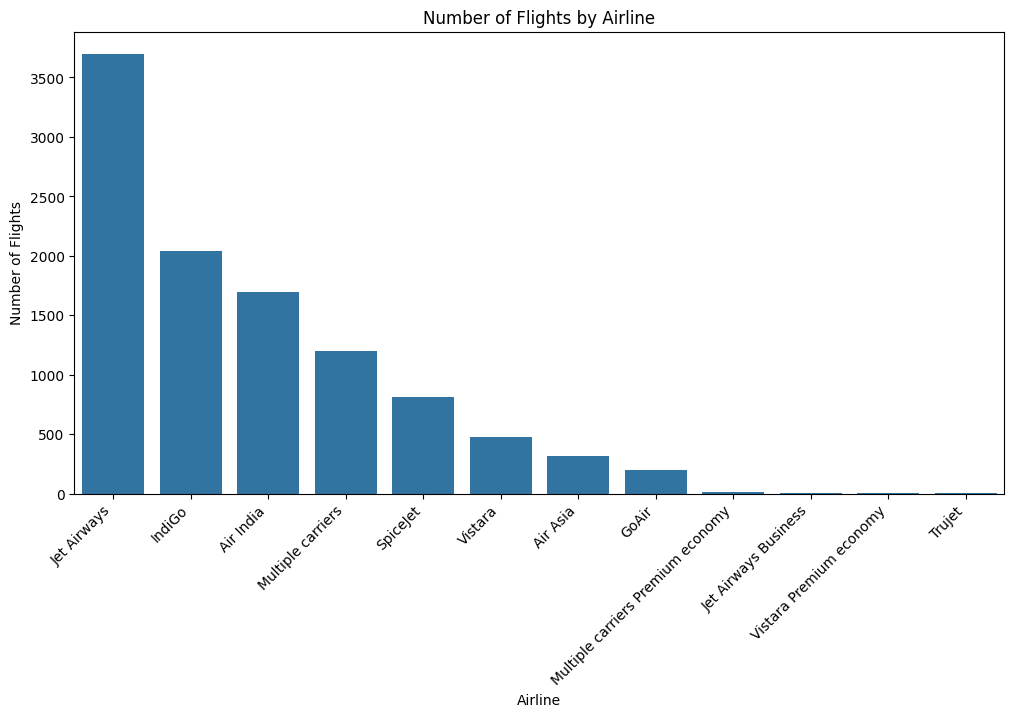

In [65]:
#countplot
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='Airline', order=df['Airline'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title('Number of Flights by Airline')
plt.xlabel('Airline')
plt.ylabel('Number of Flights')
plt.show()

Source and Destination Distribution:
The source and destination features are analysed to understand the distribution of flights across different cities.
The frequency tables and count plots show which locations have the highest number of departing and arriving flights.
This analysis helps identify the most frequently represented locations in the dataset and understand the geographical distribution of the available flight records.

In [66]:
# Count the number of flights from each source city
df['Source'].value_counts()

Source
Delhi       4345
Kolkata     2860
Banglore    2179
Mumbai       697
Chennai      381
Name: count, dtype: int64

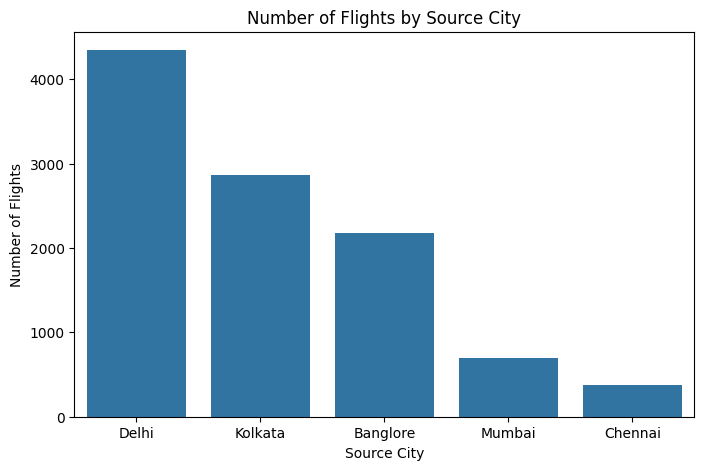

In [67]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Source',order=df['Source'].value_counts().index)
plt.title('Number of Flights by Source City')
plt.xlabel('Source City')
plt.ylabel('Number of Flights')
plt.show()

In [68]:
# Count the number of flights for each destination
df['Destination'].value_counts()

Destination
Cochin       4345
Banglore     2860
Delhi        1265
New Delhi     914
Hyderabad     697
Kolkata       381
Name: count, dtype: int64

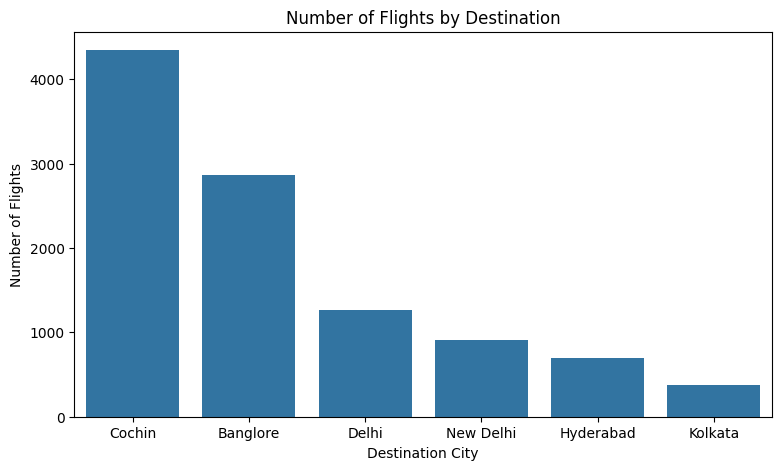

In [69]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='Destination',order=df['Destination'].value_counts().index)
plt.title('Number of Flights by Destination')
plt.xlabel('Destination City')
plt.ylabel('Number of Flights')
plt.show()

Additional Flight Information:
The `Additional_Info` feature contains details about additional services and conditions associated with flights.
The frequency distribution shows that most records have no additional information. Other categories include in-flight meals not being included, check-in baggage not being included, long layovers and business-class information.
This analysis helps understand how additional flight services and conditions are represented in the dataset.

In [70]:
# Count the occurrences of each additional information category
df['Additional_Info'].value_counts()

Additional_Info
no info                         8185
in-flight meal not included     1926
no check-in baggage included     318
1 long layover                    19
change airports                    7
business class                     4
1 short layover                    1
red-eye flight                     1
2 long layover                     1
Name: count, dtype: int64

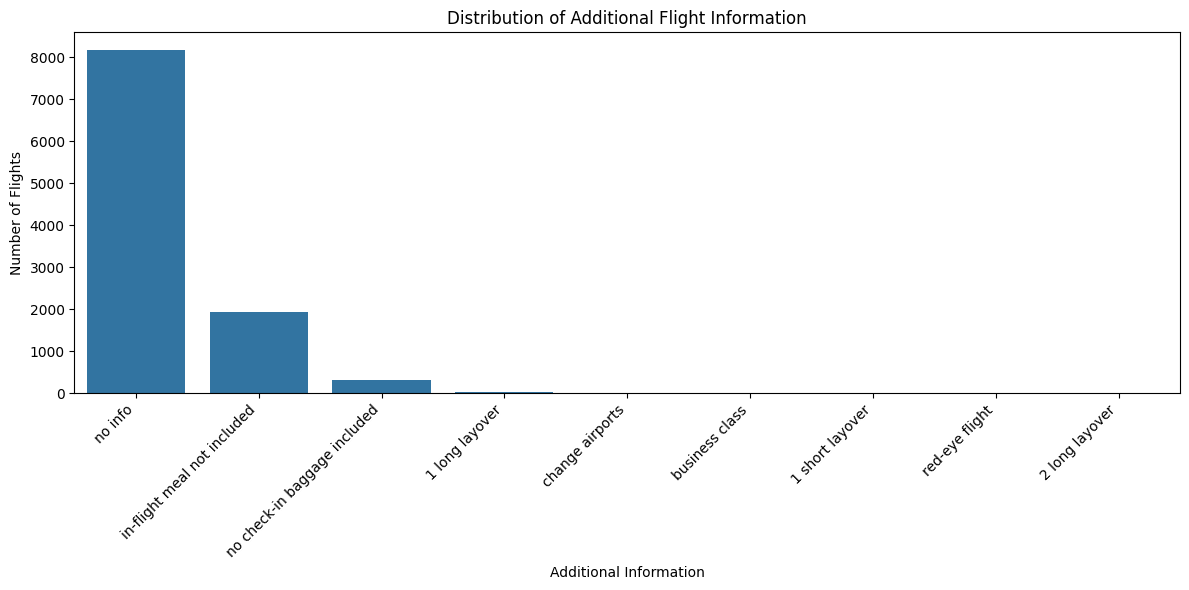

In [71]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='Additional_Info',order=df['Additional_Info'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Additional Flight Information')
plt.xlabel('Additional Information')
plt.ylabel('Number of Flights')
plt.tight_layout()
plt.show()

Flight Route Distribution:
The `Route` feature represents the sequence of locations through which a flight travels from its source to its destination.
The dataset contains 128 unique routes. The most frequent route is DEL → BOM → COK, with 2,376 records, followed by BLR → DEL, with 1,536 records.
A bar chart is used to display the ten most frequently occurring routes.
This analysis helps identify common travel routes in the dataset.

In [72]:
# Count the number of flights for each route
df['Route'].value_counts()


Route
DEL → BOM → COK          2376
BLR → DEL                1536
CCU → BOM → BLR           979
CCU → BLR                 724
BOM → HYD                 621
                         ... 
CCU → VTZ → BLR             1
CCU → IXZ → MAA → BLR       1
BOM → COK → MAA → HYD       1
BOM → CCU → HYD             1
BOM → BBI → HYD             1
Name: count, Length: 128, dtype: int64

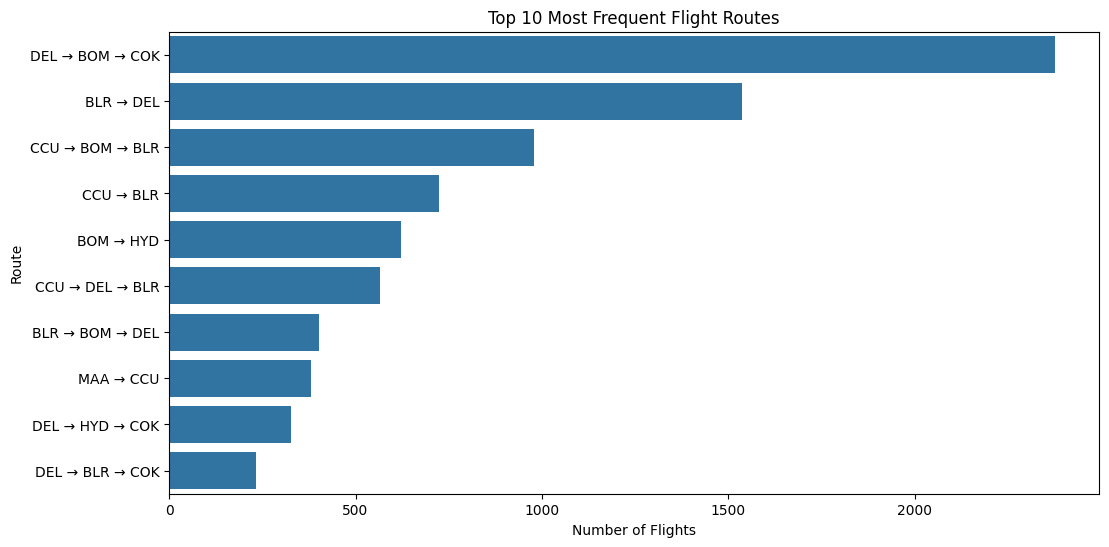

In [73]:
top_routes = df['Route'].value_counts().head(10)
plt.figure(figsize=(12, 6))
sns.barplot(x=top_routes.values, y=top_routes.index)
plt.title('Top 10 Most Frequent Flight Routes')
plt.xlabel('Number of Flights')
plt.ylabel('Route')
plt.show()

Distribution of Total Stops:
The `Total_Stops` feature indicates how many stops a flight makes between its source and destination.
The dataset contains:
- 3,475 non-stop flights.
- 5,625 flights with one stop.
- 1,318 flights with two stops.
- 43 flights with three stops.
- 1 flight with four stops.

Flights with one stop are the most common, followed by non-stop flights. The count plot helps visualise the distribution of flights based on the number of stops.

In [74]:
# Count the number of flights for each stop category
df['Total_Stops'].value_counts().sort_index()

Total_Stops
0    3475
1    5625
2    1318
3      43
4       1
Name: count, dtype: int64

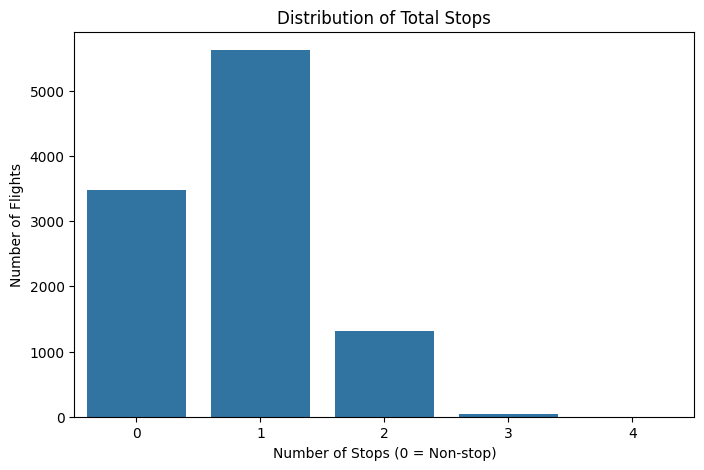

In [75]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Total_Stops',order=sorted(df['Total_Stops'].unique()))
plt.title('Distribution of Total Stops')
plt.xlabel('Number of Stops (0 = Non-stop)')
plt.ylabel('Number of Flights')
plt.show()

Journey Date Distribution:
The journey date features are analysed to understand how flight records are distributed across different months and days.
The dataset contains flights from March to June 2019.
The monthly distribution is:
- March: 2,678 flights
- April: 1,078 flights
- May: 3,395 flights
- June: 3,311 flights

May has the highest number of flight records, followed by June. April has the lowest number of records.
The monthly and daily distribution charts help identify how journey dates are represented in the dataset.

In [76]:
# Count flights for each journey month
df['Journey_Month'].value_counts().sort_index()

Journey_Month
3    2678
4    1078
5    3395
6    3311
Name: count, dtype: int64

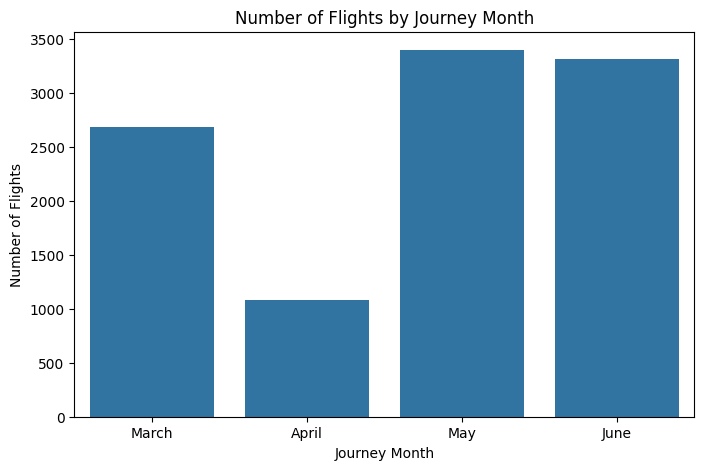

In [77]:
month_names = {
    3: 'March',
    4: 'April',
    5: 'May',
    6: 'June'
}
month_counts = df['Journey_Month'].value_counts().sort_index()
month_counts.index = month_counts.index.map(month_names)
plt.figure(figsize=(8, 5))
sns.barplot(x=month_counts.index, y=month_counts.values)
plt.title('Number of Flights by Journey Month')
plt.xlabel('Journey Month')
plt.ylabel('Number of Flights')
plt.show()

In [78]:
# Count flights for each journey day
df['Journey_Day'].value_counts().sort_index()

Journey_Day
1     1058
3      835
6     1268
9     1375
12     946
15     967
18     814
21    1085
24    1022
27    1092
Name: count, dtype: int64

Flight Duration Analysis:
Flight duration represents the total time taken by a flight to travel from its source to its destination.
In this project, flight duration was converted into total minutes to make it easier to analyse.
The statistical summary shows:
- Mean duration: approximately 629.78 minutes.
- Median duration: 505 minutes.
- Minimum duration: 5 minutes.
- Maximum duration: 2,860 minutes.
- Standard deviation: approximately 500.70 minutes.

A boxplot is used to examine the distribution of flight durations and identify unusually long or short journeys.
This analysis helps us understand the variation in journey duration across the dataset.

In [79]:
numeric_cols = [
    'Journey_Day',
    'Journey_Year',
    'Dep_Hour',
    'Dep_Minute',
    'Arrival_Hour',
    'Arrival_Minute',
    'Duration_Total_Minutes'
]
df[numeric_cols].describe()

,Journey_Day,Journey_Year,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Total_Minutes
count,10462.000000,10462.0,10462.000000,10462.000000,10462.000000,10462.000000,10462.000000
mean,13.463200,2019.0,12.478494,24.404989,13.387689,24.719939,629.781591
std,8.467493,0.0,5.727227,18.815719,6.855547,16.570450,500.699045
min,1.000000,2019.0,0.000000,0.000000,0.000000,0.000000,5.000000
25%,6.000000,2019.0,8.000000,5.000000,8.000000,10.000000,170.000000
50%,12.000000,2019.0,11.000000,25.000000,14.000000,25.000000,505.000000
75%,21.000000,2019.0,18.000000,40.000000,19.000000,35.000000,910.000000
max,27.000000,2019.0,23.000000,55.000000,23.000000,55.000000,2860.000000


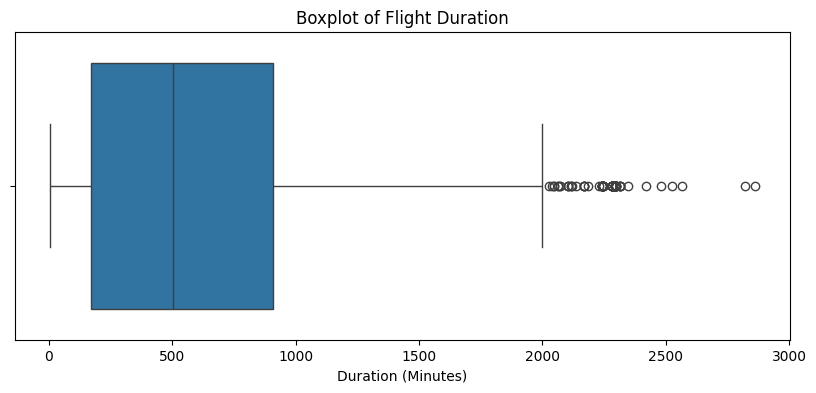

In [80]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Duration_Total_Minutes'])
plt.title('Boxplot of Flight Duration')
plt.xlabel('Duration (Minutes)')
plt.show()

Bivariate Analysis:
Bivariate analysis examines the relationship between two variables. In this project, it is used to understand how different flight features influence or relate to ticket prices.
The analysis includes:
- Average price by airline.
- Average price by source and destination.
- Average price based on the number of stops.
- Average price based on additional flight information.
- Relationship between journey month, journey day and flight price.
- Relationship between departure time, arrival time, flight duration and price.

Bar charts, scatter plots and correlation calculations are used to examine these relationships.

Average Flight Price by Airline:
The average flight price is calculated for each airline to understand how ticket prices vary across different airlines.
The analysis shows that:
- Jet Airways Business has the highest average price, approximately ₹58,358.67.
- Jet Airways has an average price of approximately ₹11,599.02.
- Multiple Carriers has an average price of approximately ₹10,902.68.
- SpiceJet has an average price of approximately ₹4,335.84.
- Trujet has the lowest average price, approximately ₹4,140.

The bar chart helps compare the average ticket prices across airlines.
Airlines with very few records should be interpreted carefully because their average prices may not represent typical fares.

In [81]:
airline_price = df.groupby('Airline')['Price'].mean()
airline_price = airline_price.sort_values(ascending=False)
airline_price

Airline
Jet Airways Business                 58358.666667
Jet Airways                          11599.021081
Multiple carriers Premium economy    11418.846154
Multiple carriers                    10902.678094
Air India                             9556.608028
Vistara Premium economy               8962.333333
Vistara                               7801.355649
GoAir                                 5861.056701
IndiGo                                5668.469897
Air Asia                              5590.260188
SpiceJet                              4335.841718
Trujet                                4140.000000
Name: Price, dtype: float64

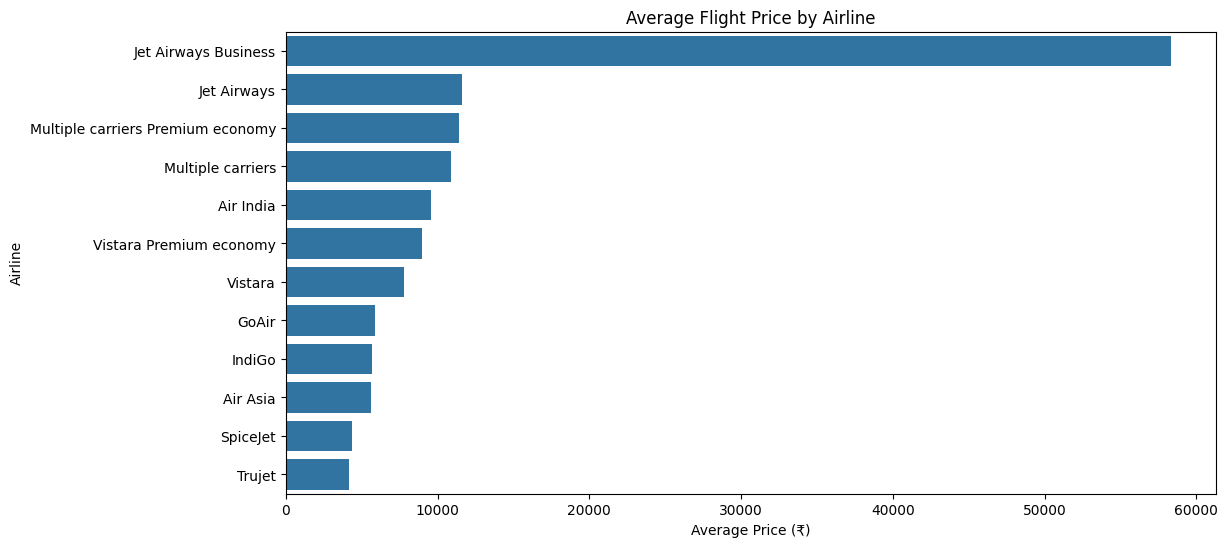

In [82]:
plt.figure(figsize=(12, 6))
sns.barplot(x=airline_price.values, y=airline_price.index)
plt.title('Average Flight Price by Airline')
plt.xlabel('Average Price (₹)')
plt.ylabel('Airline')
plt.show()

Average Flight Price by Source and Destination
The average flight prices are calculated for different source and destination locations to understand how geographical factors relate to ticket prices.
**Average price by source:**
- Delhi: approximately ₹10,461.60
- Kolkata: approximately ₹9,143.08
- Bangalore: approximately ₹8,022.87
- Mumbai: approximately ₹5,059.71
- Chennai: approximately ₹4,789.89
  
The analysis shows differences in average prices across locations. These differences may be related to the routes and airlines represented in the dataset.
Bar charts are used to compare the average prices for different source and destination locations.

In [83]:
source_price = df.groupby('Source')['Price'].mean()
source_price = source_price.sort_values(ascending=False)
source_price

Source
Delhi       10461.600690
Kolkata      9143.083566
Banglore     8022.872877
Mumbai       5059.708752
Chennai      4789.892388
Name: Price, dtype: float64

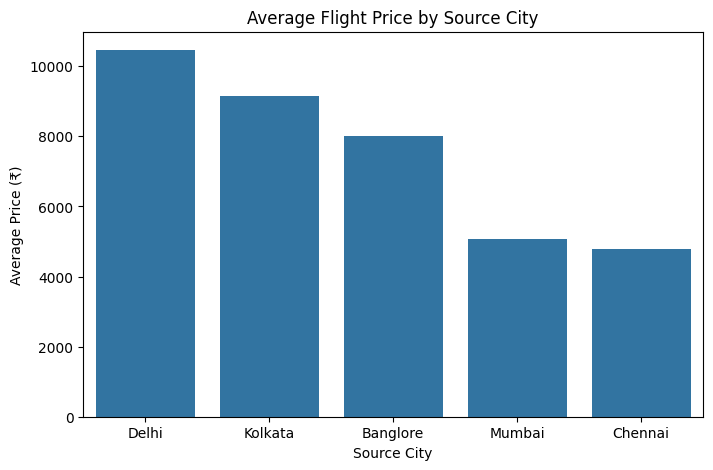

In [84]:
plt.figure(figsize=(8, 5))
sns.barplot(x=source_price.index, y=source_price.values)
plt.title('Average Flight Price by Source City')
plt.xlabel('Source City')
plt.ylabel('Average Price (₹)')
plt.show()

In [85]:
destination_price = df.groupby('Destination')['Price'].mean()
destination_price = destination_price.sort_values(ascending=False)
destination_price

Destination
New Delhi    12007.421225
Cochin       10461.600690
Banglore      9143.083566
Delhi         5143.918577
Hyderabad     5059.708752
Kolkata       4789.892388
Name: Price, dtype: float64

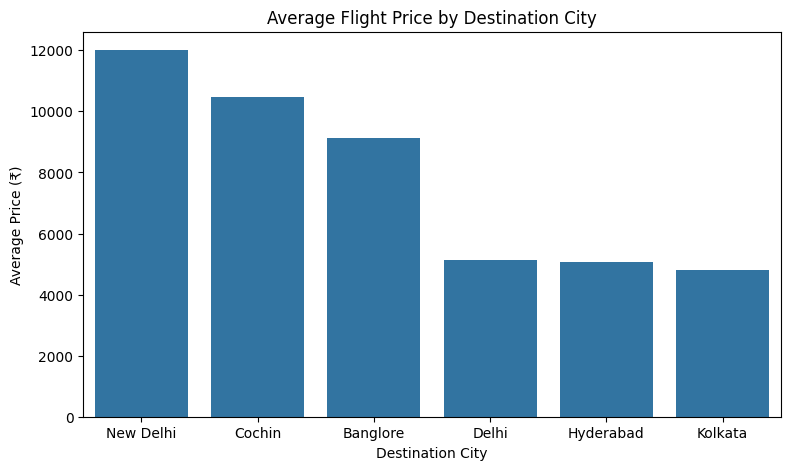

In [86]:
plt.figure(figsize=(9, 5))
sns.barplot(x=destination_price.index, y=destination_price.values)
plt.title('Average Flight Price by Destination City')
plt.xlabel('Destination City')
plt.ylabel('Average Price (₹)')
plt.show()

Average Flight Price by Number of Stops:
The average ticket price is calculated based on the number of stops to understand how flight prices vary with different journey configurations.
The analysis shows:
- Non-stop flights: approximately ₹5,018.51.
- One-stop flights: approximately ₹10,594.12.
- Two-stop flights: approximately ₹12,761.10.
- Three-stop flights: approximately ₹13,260.67.
- Four-stop flights: approximately ₹17,686.

The average price generally increases with the number of stops in this dataset.
However, the three-stop and four-stop categories contain very few records, so their averages should be interpreted cautiously.
A bar chart is used to compare average prices across the different stop categories.

In [87]:
# Calculate the average flight price for each number of stops
stops_price = df.groupby('Total_Stops')['Price'].mean()
stops_price

Total_Stops
0     5018.506763
1    10594.123556
2    12761.099393
3    13260.674419
4    17686.000000
Name: Price, dtype: float64

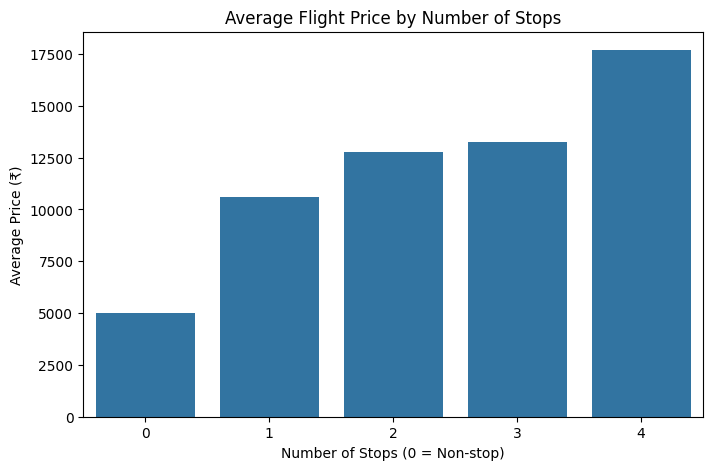

In [88]:
plt.figure(figsize=(8, 5))
sns.barplot(x=stops_price.index, y=stops_price.values)
plt.title('Average Flight Price by Number of Stops')
plt.xlabel('Number of Stops (0 = Non-stop)')
plt.ylabel('Average Price (₹)')
plt.show()

Average Flight Price by Additional Information:
The average flight price is calculated for each category of `Additional_Info` to understand how additional flight services and conditions relate to ticket prices.
The comparison helps identify whether categories such as business class, in-flight meal information and baggage information are associated with differences in average flight prices.
A bar chart is used to visualise the average price across the different categories.
These observations show associations in the dataset and do not necessarily indicate that additional services directly cause higher or lower prices.

In [89]:
# Calculate the average flight price for each additional information category
info_price = df.groupby('Additional_Info')['Price'].mean()
info_price = info_price.sort_values(ascending=False)
info_price

Additional_Info
business class                  56811.250000
1 short layover                 26743.000000
2 long layover                  26480.000000
1 long layover                  22109.631579
change airports                 16800.714286
red-eye flight                  10873.000000
in-flight meal not included      9435.647456
no info                          9074.879658
no check-in baggage included     3642.465409
Name: Price, dtype: float64

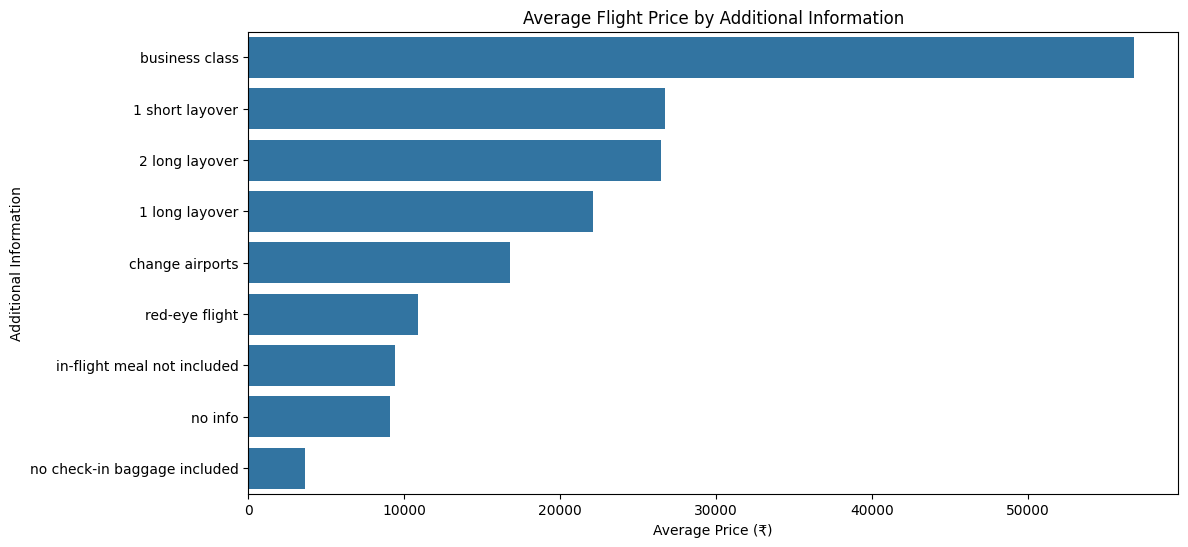

In [90]:
plt.figure(figsize=(12, 6))
sns.barplot(x=info_price.values, y=info_price.index)
plt.title('Average Flight Price by Additional Information')
plt.xlabel('Average Price (₹)')
plt.ylabel('Additional Information')
plt.show()

Relationship Between Journey Date and Flight Price:
The average flight price is analysed across different journey months and days to understand whether ticket prices vary depending on the travel date.
The monthly analysis compares average flight prices across March, April, May and June.
The daily analysis examines how average prices vary across different days of the month.
Bar charts are used to visualise these patterns and identify possible variations in flight prices based on journey dates.

In [91]:
# Calculate average flight price for each journey month
month_price = df.groupby('Journey_Month')['Price'].mean()
month_price

Journey_Month
3    10695.397311
4     5766.545455
5     9029.239764
6     8736.152522
Name: Price, dtype: float64

In [92]:
# Calculate average flight price for each journey day
day_price = df.groupby('Journey_Day')['Price'].mean()
day_price

Journey_Day
1     10457.094518
3      9022.713772
6     10364.533912
9      9474.560000
12     9080.340381
15     8061.858325
18     8561.388206
21     8275.211982
24     8350.679061
27     8061.511905
Name: Price, dtype: float64

Relationship Between Departure Time, Arrival Time and Flight Price:
Departure and arrival hours are analysed to understand how flight prices vary depending on the time of travel.
The average prices are calculated for different departure hours and arrival hours.
The analysis helps identify whether flights scheduled at particular times of the day have different average prices.
Bar charts are used to visualise the relationship between departure time, arrival time and flight prices.

In [93]:
# Calculate average flight price for each departure hour
departure_price = df.groupby('Dep_Hour')['Price'].mean()
departure_price

Dep_Hour
0      7615.075000
1      4354.621622
2      8419.974227
3     10474.625000
4      7266.520710
5      9480.309278
6      8252.195556
7      8485.902665
8     10073.923631
9      9559.092551
10     8870.728653
11     9296.739206
12     9251.573034
13     8998.725061
14     9816.409901
15     7687.410658
16    10330.783080
17     8710.355588
18    10043.981859
19     8344.700368
20     9683.838213
21     8450.296524
22     7765.975871
23     8487.338346
Name: Price, dtype: float64

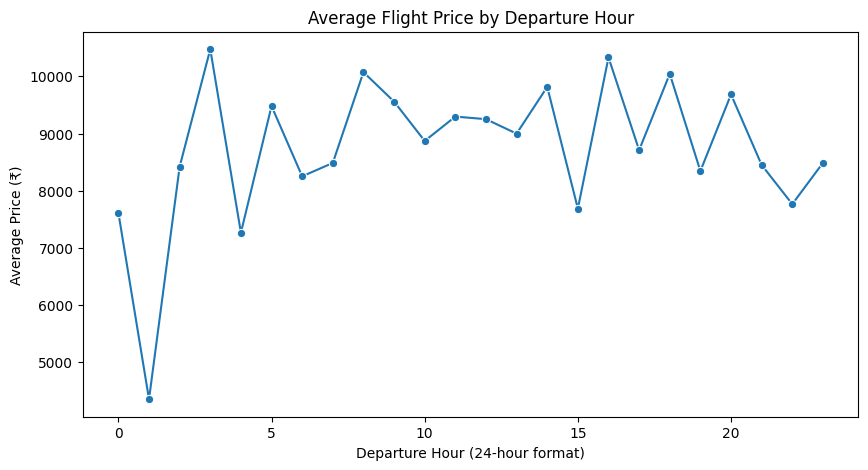

In [94]:
plt.figure(figsize=(10, 5))
sns.lineplot(x=departure_price.index, y=departure_price.values, marker='o')
plt.title('Average Flight Price by Departure Hour')
plt.xlabel('Departure Hour (24-hour format)')
plt.ylabel('Average Price (₹)')
plt.show()

In [95]:
# Count how many flights depart in each hour
departure_count = df['Dep_Hour'].value_counts().sort_index()
print(departure_count)

Dep_Hour
0      40
1      37
2     194
3      24
4     169
5     582
6     675
7     863
8     694
9     886
10    527
11    579
12    178
13    411
14    505
15    319
16    461
17    689
18    441
19    544
20    649
21    489
22    373
23    133
Name: count, dtype: int64


In [96]:
# Calculate the average flight price for each arrival hour
arrival_price = df.groupby('Arrival_Hour')['Price'].mean()
print(arrival_price)

Arrival_Hour
0      5642.447205
1      9636.845714
2      5151.886076
3      4934.638298
4     11355.286465
5     15532.151515
6      5819.470588
7      7796.538647
8      8051.175214
9      9203.018405
10     8118.831224
11     7417.629630
12     9560.559814
13     7499.521452
14     6627.581633
15     8925.412088
16     9272.121622
17     5820.633508
18    10612.119843
19    10936.235521
20     8267.570292
21     8676.784593
22     7575.583591
23     8947.058212
Name: Price, dtype: float64


In [97]:
# Count the number of flights for each arrival hour
arrival_count = df['Arrival_Hour'].value_counts().sort_index()
print(arrival_count)

Arrival_Hour
0      322
1      525
2       79
3       47
4      761
5       66
6       51
7      414
8      468
9      489
10     474
11     297
12     861
13     303
14     294
15     182
16     370
17     191
18     509
19    1554
20     377
21     701
22     646
23     481
Name: count, dtype: int64


Relationship Between Flight Duration and Price:
The relationship between flight duration and ticket price is examined using correlation analysis and a scatter plot.
The correlation coefficient between flight duration and price is approximately 0.502, indicating a moderate positive relationship.
This suggests that longer flights tend to have higher ticket prices in this dataset. However, the scatter plot also shows variation in prices for flights with similar durations.
Flight duration alone cannot explain all the differences in ticket prices, as other factors such as airline, route and number of stops may also contribute.

In [98]:
# Calculate the correlation between flight duration and price
duration_price_corr = df['Duration_Total_Minutes'].corr(df['Price'])
print(duration_price_corr)

0.5017579376022411


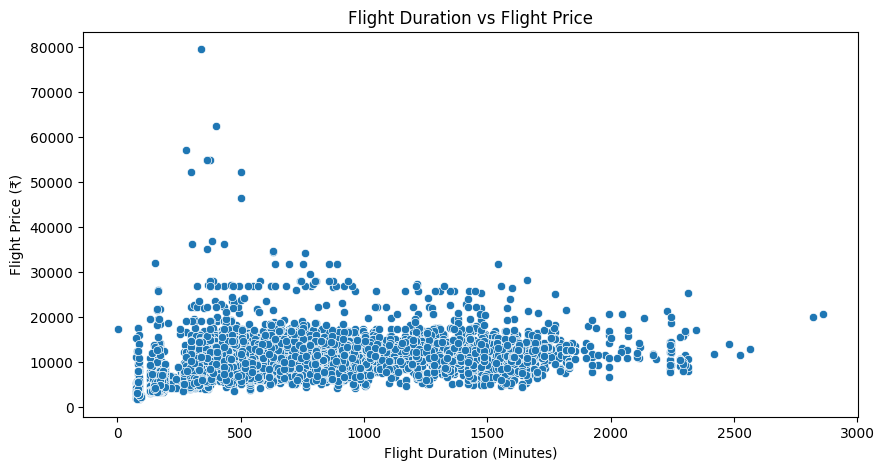

In [99]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Duration_Total_Minutes', y='Price')
plt.title('Flight Duration vs Flight Price')
plt.xlabel('Flight Duration (Minutes)')
plt.ylabel('Flight Price (₹)')
plt.show()

In [100]:
# Find rows where flight duration is zero
zero_duration = df[df['Duration_Total_Minutes'] == 0]
print("Number of zero-duration flights:", len(zero_duration))
print(zero_duration)

Number of zero-duration flights: 0
Empty DataFrame
Columns: [Airline, Source, Destination, Route, Total_Stops, Additional_Info, Price, Journey_Day, Journey_Month, Journey_Year, Dep_Hour, Dep_Minute, Arrival_Hour, Arrival_Minute, Duration_Total_Minutes]
Index: []


In [101]:
# Select flights with prices above ₹30,000
expensive_flights = df[df['Price'] > 30000]
print(expensive_flights[
    ['Airline', 'Route', 'Additional_Info',
     'Duration_Total_Minutes', 'Price']
])

                    Airline                  Route Additional_Info  \
396       Multiple carriers        DEL → BOM → COK         no info   
657    Jet Airways Business        BLR → BOM → DEL         no info   
1478            Jet Airways        BLR → BOM → DEL         no info   
1629              Air India  BLR → BOM → NAG → DEL         no info   
2099            Jet Airways        BLR → BOM → DEL         no info   
2618            Jet Airways        BLR → BOM → DEL         no info   
2693            Jet Airways        BLR → BOM → DEL         no info   
2924   Jet Airways Business        BLR → BOM → DEL  business class   
3700            Jet Airways        BLR → BOM → DEL  1 long layover   
5013            Jet Airways        BLR → BOM → DEL  1 long layover   
5372   Jet Airways Business        BLR → BOM → DEL  business class   
5439            Jet Airways        BLR → BOM → DEL         no info   
5662            Jet Airways        BLR → BOM → DEL         no info   
5719            Jet 

Relationship Between Departure Minutes, Arrival Minutes and Price:
The relationship between departure minutes, arrival minutes and flight prices is examined using correlation analysis.
The observed correlations are:
- Departure minute and price: approximately -0.024.
- Arrival minute and price: approximately -0.086.

Both values are close to zero, indicating very weak linear relationships between minute-level timing and flight prices in this dataset.
This suggests that departure and arrival minutes alone provide little information about variations in ticket prices.

In [102]:
# Calculate the correlation between departure minute and price
print("Departure minute correlation:", df['Dep_Minute'].corr(df['Price']))

# Calculate the correlation between arrival minute and price
print("Arrival minute correlation:", df['Arrival_Minute'].corr(df['Price']))

Departure minute correlation: -0.024155412702532204
Arrival minute correlation: -0.08616347309843159


Multivariate Analysis:
Multivariate analysis examines the relationships between three or more variables simultaneously.
In this project, it helps us understand how combinations of flight features are associated with ticket prices.
The analysis includes:
- Relationship between airline, number of stops and price.
- Relationship between airline, source and destination.
- Relationship between airline, journey month and price.
- 
Grouping and visualisation techniques are used to identify patterns across multiple flight features.

Relationship Between Airline, Total Stops and Price:
The relationship between airline, number of stops and flight price is analysed to understand how these features vary together.
Grouping the data by airline and number of stops helps compare average ticket prices across different flight categories.
The analysis provides a better understanding of how airline choice and journey configuration are associated with flight prices.
Categories containing very few records should be interpreted cautiously because their average prices may not represent typical fares.

In [103]:
# Group the data by airline and number of stops
# Calculate the average price for each combination
airline_stops_price = df.groupby(
    ['Airline', 'Total_Stops']
)['Price'].mean()
print(airline_stops_price)

Airline                            Total_Stops
Air Asia                           0               4492.331492
                                   1               7078.325581
                                   2               6341.888889
Air India                          0               5600.552885
                                   1               9041.509259
                                   2              12146.860399
                                   3              12339.057143
                                   4              17686.000000
GoAir                              0               4726.173913
                                   1               6884.676471
IndiGo                             0               4714.865963
                                   1               7104.717528
                                   2               7507.526316
Jet Airways                        0               6173.384244
                                   1              12512.741223
        

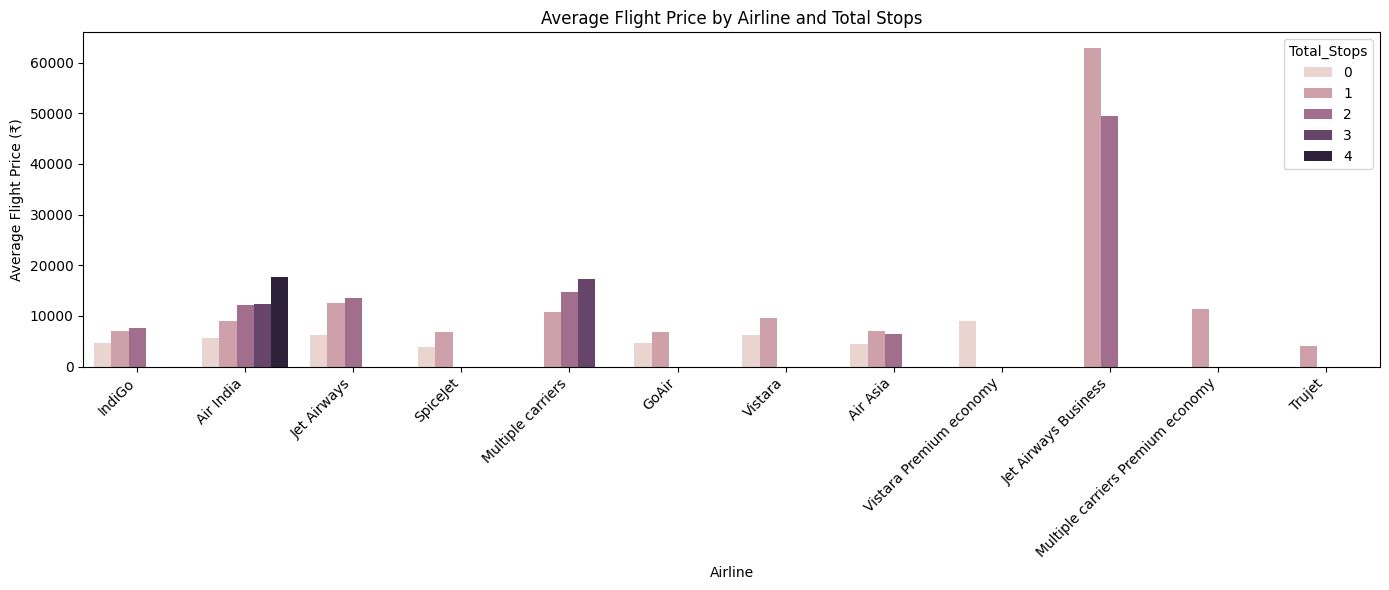

In [104]:
plt.figure(figsize=(14, 6))
sns.barplot(
    data=df,
    x='Airline',
    y='Price',
    hue='Total_Stops',
    errorbar=None
)
plt.title('Average Flight Price by Airline and Total Stops')
plt.xlabel('Airline')
plt.ylabel('Average Flight Price (₹)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [105]:
# Find airline categories that mention Business or Premium economy
special_airlines = df[
    df['Airline'].str.contains(
        'Business|Premium economy',
        case=False,
        na=False
    )
]

# Display the airline and additional information
print(
    special_airlines[
        ['Airline', 'Additional_Info', 'Price']
    ].to_string(index=False)
)

# Count the records in each special airline category
print("\nCategory counts:")
print(special_airlines['Airline'].value_counts())

                          Airline Additional_Info  Price
          Vistara Premium economy         no info  11793
             Jet Airways Business         no info  52229
Multiple carriers Premium economy         no info  10161
Multiple carriers Premium economy         no info   9845
             Jet Airways Business  business class  79512
Multiple carriers Premium economy         no info  10161
Multiple carriers Premium economy         no info   9845
Multiple carriers Premium economy         no info  11269
             Jet Airways Business  business class  62427
Multiple carriers Premium economy         no info  11269
Multiple carriers Premium economy         no info  14629
Multiple carriers Premium economy         no info  14629
Multiple carriers Premium economy         no info   9845
Multiple carriers Premium economy         no info  11269
Multiple carriers Premium economy         no info  13369
             Jet Airways Business         no info  46490
          Vistara Premium econo

In [106]:
# Group flights by source and destination
# Calculate the average price for each source-destination combination
route_price = df.groupby(
    ['Source', 'Destination']
)['Price'].mean().sort_values(ascending=False)
print(route_price)

Source    Destination
Banglore  New Delhi      12007.421225
Delhi     Cochin         10461.600690
Kolkata   Banglore        9143.083566
Banglore  Delhi           5143.918577
Mumbai    Hyderabad       5059.708752
Chennai   Kolkata         4789.892388
Name: Price, dtype: float64


Relationship Between Airline, Source, Destination and Price:
The relationship between airline, source, destination and flight price is examined to understand how these features vary together.
Grouping the data by airline, source and destination helps compare average ticket prices for different travel combinations.
This analysis helps identify how flight prices differ across airlines and geographical routes.
The results represent patterns in the available dataset and may not apply to every flight or travel date.

In [107]:
# Group flights by airline, source, and destination
# Calculate the average price for each combination
airline_route_price = df.groupby(
    ['Airline', 'Source', 'Destination']
)['Price'].mean().sort_values(ascending=False)
print(airline_route_price.head(15))

Airline                            Source    Destination
Jet Airways Business               Banglore  New Delhi      62844.250000
                                   Delhi     Cochin         49387.500000
Jet Airways                        Banglore  New Delhi      15120.151079
                                   Delhi     Cochin         12626.772601
Vistara                            Mumbai    Hyderabad      12326.521739
Vistara Premium economy            Banglore  New Delhi      11793.000000
Jet Airways                        Kolkata   Banglore       11717.565287
Multiple carriers Premium economy  Delhi     Cochin         11418.846154
Air India                          Banglore  New Delhi      11024.679426
Multiple carriers                  Delhi     Cochin         10902.678094
Air India                          Kolkata   Banglore       10296.273453
                                   Delhi     Cochin          9960.348506
Vistara                            Kolkata   Banglore        9257.6

Relationship Between Airline, Journey Month and Price:
The relationship between airline, journey month and flight price is analysed to understand how average ticket prices vary across different airlines and travel months.
Grouping the data by airline and journey month helps identify seasonal price variations and differences between airlines.
The analysis also examines the number of flight records available for each airline-month combination.
These patterns can help us understand how airline choice and travel month are associated with flight prices.

In [108]:
# Group flights by airline and journey month
# Calculate the average price for each combination
airline_month_price = df.groupby(
    ['Airline', 'Journey_Month']
)['Price'].mean()
print(airline_month_price)

Airline                            Journey_Month
Air Asia                           3                 5988.016667
                                   4                 4729.362069
                                   5                 5174.346154
                                   6                 6304.917526
Air India                          3                10688.296512
                                   4                 6222.299320
                                   5                 9689.385435
                                   6                 9196.433761
GoAir                              3                 8124.275000
                                   4                 4953.431818
                                   5                 5812.220000
                                   6                 5058.533333
IndiGo                             3                 7220.833034
                                   4                 4779.929712
                                   5     

In [109]:
# Group flights by airline and journey month
# Count the number of flights in each combination
airline_month_count = df.groupby(
    ['Airline', 'Journey_Month']
).size()
print(airline_month_count)

Airline                            Journey_Month
Air Asia                           3                  60
                                   4                  58
                                   5                 104
                                   6                  97
Air India                          3                 516
                                   4                 147
                                   5                 563
                                   6                 468
GoAir                              3                  40
                                   4                  44
                                   5                  50
                                   6                  60
IndiGo                             3                 557
                                   4                 313
                                   5                 562
                                   6                 611
Jet Airways                        3   

Summary of Exploratory Data Analysis:
The exploratory data analysis highlights several patterns in the flight dataset:

- Flight prices have a right-skewed distribution, with a small number of high-priced records.
- Jet Airways has the highest number of records in the dataset.
- Flights with one stop are the most common.
- Flight duration has a moderate positive relationship with price.
- Departure and arrival minutes have very weak linear relationships with price.
- Average flight prices vary across airlines, routes, journey months and number of stops.

These findings help identify useful features and relationships for the next stages of feature engineering and model development.

Feature Engineering:
Feature engineering is the process of creating useful features from the existing dataset to improve the information available for machine learning models.
In this project, additional date and time features are created from the existing journey date, departure time and arrival time information.
The following steps are performed:
- Reconstruct the journey date using the year, month and day columns.
- Extract the day of the week from the journey date.
- Create a weekend indicator to distinguish weekday and weekend journeys.
- Classify departure times into Morning, Afternoon, Evening and Night.
- Classify arrival times into Morning, Afternoon, Evening and Night.

These additional features help explore different aspects of flight schedules and journey dates.

In [110]:
df.dtypes

Airline                   object
Source                    object
Destination               object
Route                     object
Total_Stops                int64
Additional_Info           object
Price                      int64
Journey_Day                int32
Journey_Month              int32
Journey_Year               int32
Dep_Hour                   int32
Dep_Minute                 int32
Arrival_Hour               int32
Arrival_Minute             int32
Duration_Total_Minutes     int64
dtype: object

In [111]:
# Reconstruct the journey date using year, month, and day
df['Journey_Date'] = pd.to_datetime(
    df[['Journey_Year', 'Journey_Month', 'Journey_Day']].rename(
        columns={
            'Journey_Year': 'year',
            'Journey_Month': 'month',
            'Journey_Day': 'day'
        }
    )
)
print(df[['Journey_Year', 'Journey_Month', 'Journey_Day', 'Journey_Date']].head())

   Journey_Year  Journey_Month  Journey_Day Journey_Date
0          2019              3           24   2019-03-24
1          2019              5            1   2019-05-01
2          2019              6            9   2019-06-09
3          2019              5           12   2019-05-12
4          2019              3            1   2019-03-01


In [112]:
# Extract the day of the week from Journey_Date
df['Journey_Weekday'] = df['Journey_Date'].dt.dayofweek
df['Is_Weekend'] = df['Journey_Weekday'].isin([5, 6]).astype(int)
print(df[['Journey_Date', 'Journey_Weekday', 'Is_Weekend']].head(10))

  Journey_Date  Journey_Weekday  Is_Weekend
0   2019-03-24                6           1
1   2019-05-01                2           0
2   2019-06-09                6           1
3   2019-05-12                6           1
4   2019-03-01                4           0
5   2019-06-24                0           0
6   2019-03-12                1           0
7   2019-03-01                4           0
8   2019-03-12                1           0
9   2019-05-27                0           0


In [113]:
# Count weekday and weekend flights
print(df['Is_Weekend'].value_counts())
print(df['Is_Weekend'].value_counts(normalize=True) * 100)

Is_Weekend
0    7390
1    3072
Name: count, dtype: int64
Is_Weekend
0    70.63659
1    29.36341
Name: proportion, dtype: float64


In [114]:
# Calculate average flight price for weekdays and weekends
weekend_price = df.groupby('Is_Weekend')['Price'].mean()
print(weekend_price)

Is_Weekend
0    8960.804195
1    9185.526367
Name: Price, dtype: float64


In [115]:
# Function to classify departure hours into time periods
def get_dep_period(hour):
    if 5 <= hour <= 11:
        return 'Morning'
    elif 12 <= hour <= 16:
        return 'Afternoon'
    elif 17 <= hour <= 20:
        return 'Evening'
    else:
        return 'Night'

# Apply the function to every row in Dep_Hour
df['Dep_Period'] = df['Dep_Hour'].apply(get_dep_period)
# Display departure hours and their corresponding periods
print(df[['Dep_Hour', 'Dep_Period']].head(15))

    Dep_Hour Dep_Period
0         22      Night
1          5    Morning
2          9    Morning
3         18    Evening
4         16  Afternoon
5          9    Morning
6         18    Evening
7          8    Morning
8          8    Morning
9         11    Morning
10         9    Morning
11        20    Evening
12        11    Morning
13        21      Night
14        17    Evening


In [116]:
# Count flights in each departure period
print(df['Dep_Period'].value_counts())

Dep_Period
Morning      4806
Evening      2323
Afternoon    1874
Night        1459
Name: count, dtype: int64


In [117]:
# Function to classify arrival hours into time periods
def get_arrival_period(hour):

    if 5 <= hour <= 11:
        return 'Morning'

    elif 12 <= hour <= 16:
        return 'Afternoon'

    elif 17 <= hour <= 20:
        return 'Evening'

    else:
        return 'Night'


# Apply the function to every row in Arrival_Hour
df['Arrival_Period'] = df['Arrival_Hour'].apply(get_arrival_period)
# Display arrival hours and their corresponding periods
print(df[['Arrival_Hour', 'Arrival_Period']].head(15))

    Arrival_Hour Arrival_Period
0              1          Night
1             13      Afternoon
2              4          Night
3             23          Night
4             21          Night
5             11        Morning
6             10        Morning
7              5        Morning
8             10        Morning
9             19        Evening
10            23          Night
11            22          Night
12            13      Afternoon
13             9        Morning
14            19        Evening


In [118]:
# Count flights in each arrival period
print(df['Arrival_Period'].value_counts())


Arrival_Period
Night        3562
Evening      2631
Morning      2259
Afternoon    2010
Name: count, dtype: int64


In [119]:
# Display the first 10 route values
print(df['Route'].head(10))

0                BLR → DEL
1    CCU → IXR → BBI → BLR
2    DEL → LKO → BOM → COK
3          CCU → NAG → BLR
4          BLR → NAG → DEL
5                CCU → BLR
6          BLR → BOM → DEL
7          BLR → BOM → DEL
8          BLR → BOM → DEL
9          DEL → BOM → COK
Name: Route, dtype: object


In [120]:
# Display all column names
df.columns

Index(['Airline', 'Source', 'Destination', 'Route', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_Day', 'Journey_Month',
       'Journey_Year', 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour',
       'Arrival_Minute', 'Duration_Total_Minutes', 'Journey_Date',
       'Journey_Weekday', 'Is_Weekend', 'Dep_Period', 'Arrival_Period'],
      dtype='object')

In [121]:
df.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Total_Minutes,Journey_Date,Journey_Weekday,Is_Weekend,Dep_Period,Arrival_Period
0,IndiGo,Banglore,New Delhi,BLR → DEL,0,no info,3897,24,3,2019,22,20,1,10,170,2019-03-24,6,1,Night,Night
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2,no info,7662,1,5,2019,5,50,13,15,445,2019-05-01,2,0,Morning,Afternoon
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2,no info,13882,9,6,2019,9,25,4,25,1140,2019-06-09,6,1,Morning,Night
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1,no info,6218,12,5,2019,18,5,23,30,325,2019-05-12,6,1,Evening,Night
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1,no info,13302,1,3,2019,16,50,21,35,285,2019-03-01,4,0,Afternoon,Night


In [122]:
# Count the number of unique values in each column
df.nunique()

Airline                     12
Source                       5
Destination                  6
Route                      128
Total_Stops                  5
Additional_Info              9
Price                     1870
Journey_Day                 10
Journey_Month                4
Journey_Year                 1
Dep_Hour                    24
Dep_Minute                  12
Arrival_Hour                24
Arrival_Minute              12
Duration_Total_Minutes     368
Journey_Date                40
Journey_Weekday              7
Is_Weekend                   2
Dep_Period                   4
Arrival_Period               4
dtype: int64

Feature Selection and Removal:
After creating the additional features, some columns are removed to avoid keeping unnecessary or redundant information.
The following columns are removed during this stage:
- **Journey_Year:** Removed because all records belong to the year 2019, so this column has no variation.
- **Journey_Date:** Removed after extracting the day, month and weekday information.
- **Is_Weekend:** Removed while retaining the journey day and weekday features.
- **Dep_Period:** Removed while retaining the detailed departure hour and minute features.
- **Arrival_Period:** Removed while retaining the detailed arrival hour and minute features.

The remaining features are used for further preprocessing and model development.

In [123]:
df.drop(columns=['Journey_Year'], inplace=True)

In [124]:
df.columns

Index(['Airline', 'Source', 'Destination', 'Route', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_Day', 'Journey_Month', 'Dep_Hour',
       'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute',
       'Duration_Total_Minutes', 'Journey_Date', 'Journey_Weekday',
       'Is_Weekend', 'Dep_Period', 'Arrival_Period'],
      dtype='object')

In [125]:
# Display the journey date and its related features
df[['Journey_Date', 'Journey_Day', 'Journey_Month', 'Journey_Weekday', 'Is_Weekend']].head(10)

,Journey_Date,Journey_Day,Journey_Month,Journey_Weekday,Is_Weekend
0,2019-03-24,24,3,6,1
1,2019-05-01,1,5,2,0
2,2019-06-09,9,6,6,1
3,2019-05-12,12,5,6,1
4,2019-03-01,1,3,4,0
5,2019-06-24,24,6,0,0
6,2019-03-12,12,3,1,0
7,2019-03-01,1,3,4,0
8,2019-03-12,12,3,1,0
9,2019-05-27,27,5,0,0


In [126]:
df.drop(columns=['Journey_Date', 'Is_Weekend'], inplace=True)

In [127]:
df[['Journey_Day', 'Journey_Month', 'Journey_Weekday']].head()

,Journey_Day,Journey_Month,Journey_Weekday
0,24,3,6
1,1,5,2
2,9,6,6
3,12,5,6
4,1,3,4


In [128]:
df.groupby('Dep_Period')['Price'].agg(['count', 'mean'])

,count,mean
Dep_Period,,
Afternoon,1874,9347.554963
Evening,2323,9149.874731
Morning,4806,9140.543279
Night,1459,8044.106923


In [129]:
df.drop(columns=['Dep_Period'], inplace=True)

In [130]:
df[['Dep_Hour', 'Dep_Minute']].head()

,Dep_Hour,Dep_Minute
0,22,20
1,5,50
2,9,25
3,18,5
4,16,50


In [131]:
# Group flights by arrival period and calculate count and average price
df.groupby('Arrival_Period')['Price'].agg(['count', 'mean'])

,count,mean
Arrival_Period,,
Afternoon,2010,8710.256716
Evening,2631,10119.762068
Morning,2259,8352.930500
Night,3562,8825.463223


In [132]:
df.drop(columns=['Arrival_Period'], inplace=True)
df[['Arrival_Hour', 'Arrival_Minute']].head()

,Arrival_Hour,Arrival_Minute
0,1,10
1,13,15
2,4,25
3,23,30
4,21,35


In [133]:
df['Route'].nunique()

128

In [134]:
df['Route'].value_counts().head(10)

Route
DEL → BOM → COK    2376
BLR → DEL          1536
CCU → BOM → BLR     979
CCU → BLR           724
BOM → HYD           621
CCU → DEL → BLR     565
BLR → BOM → DEL     402
MAA → CCU           381
DEL → HYD → COK     326
DEL → BLR → COK     232
Name: count, dtype: int64

In [135]:
df['Total_Stops'].value_counts().sort_index()
df['Total_Stops'].value_counts(normalize=True).sort_index() * 100

Total_Stops
0    33.215446
1    53.766010
2    12.597974
3     0.411011
4     0.009558
Name: proportion, dtype: float64

In [136]:
df.groupby('Additional_Info')['Price'].agg(['count', 'mean']).sort_values('count', ascending=False)

,count,mean
Additional_Info,,
no info,8185,9074.879658
in-flight meal not included,1926,9435.647456
no check-in baggage included,318,3642.465409
1 long layover,19,22109.631579
change airports,7,16800.714286
business class,4,56811.250000
1 short layover,1,26743.000000
2 long layover,1,26480.000000
red-eye flight,1,10873.000000


Feature Correlation Analysis:
Correlation analysis is performed to examine the linear relationships between numerical features and the target variable, `Price`.
The correlation results show that:
- **Total_Stops** has the strongest positive correlation with Price, with a correlation value of approximately **0.602**.
- **Duration_Total_Minutes** has a positive correlation of approximately **0.502** with Price.
- **Dep_Minute** and **Arrival_Minute** have very weak negative correlations with Price, with values close to zero.
- **Journey_Weekday** and **Dep_Hour** also have very weak correlations with Price.

These findings suggest that the number of stops and flight duration have stronger linear relationships with flight prices than the departure and arrival minutes.

In [137]:
df.corr(numeric_only=True)['Price'].sort_values(ascending=False)

Price                     1.000000
Total_Stops               0.602013
Duration_Total_Minutes    0.501758
Journey_Weekday           0.055846
Arrival_Hour              0.031023
Dep_Hour                  0.005155
Dep_Minute               -0.024155
Arrival_Minute           -0.086163
Journey_Month            -0.113396
Journey_Day              -0.159044
Name: Price, dtype: float64

In [138]:
len(df.columns)
df.columns.tolist()

['Airline',
 'Source',
 'Destination',
 'Route',
 'Total_Stops',
 'Additional_Info',
 'Price',
 'Journey_Day',
 'Journey_Month',
 'Dep_Hour',
 'Dep_Minute',
 'Arrival_Hour',
 'Arrival_Minute',
 'Duration_Total_Minutes',
 'Journey_Weekday']

Model Preparation and Data Preprocessing:
Before training machine learning models, the dataset must be prepared by separating the input features from the target variable and converting categorical data into numerical format.
The following steps are performed:

- Separate the independent variables (X) and dependent variable (Price).
- Identify categorical features that require encoding.
- Apply One-Hot Encoding to convert categorical features into numerical columns.
- Split the dataset into training and testing sets.
- Scale the features for Linear Regression.

These steps prepare the data for training and evaluating the machine learning models.

Separating Input Features and Target Variable:
The dataset is divided into input features and the target variable.
- **X (Independent Variables):** Contains all the columns used as input for predicting flight prices, excluding the `Price` column.
- **y (Dependent Variable):** Contains the `Price` column, which is the value the machine learning models are trained to predict.
This separation allows the models to learn the relationship between flight information and ticket prices.

In [139]:
# Data Preprocessing
# Store all input features in X by removing the Price column
X = df.drop(columns=['Price'])
y = df['Price']

In [140]:
# Check the dimensions of the input features
print("X shape:", X.shape)

# Check the dimensions of the target variable
print("y shape:", y.shape)

X shape: (10462, 14)
y shape: (10462,)


In [141]:
X.dtypes

Airline                   object
Source                    object
Destination               object
Route                     object
Total_Stops                int64
Additional_Info           object
Journey_Day                int32
Journey_Month              int32
Dep_Hour                   int32
Dep_Minute                 int32
Arrival_Hour               int32
Arrival_Minute             int32
Duration_Total_Minutes     int64
Journey_Weekday            int32
dtype: object

In [142]:
# Identify the number of unique categories in each categorical column
categorical_columns = X.select_dtypes(include=['object']).columns
for column in categorical_columns:
    print(column, ":", X[column].nunique())

Airline : 12
Source : 5
Destination : 6
Route : 128
Additional_Info : 9


In [143]:
source_encoded = pd.get_dummies(X['Source'], prefix='Source', dtype=int)
source_encoded.head()

,Source_Banglore,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai
0,1,0,0,0,0
1,0,0,0,1,0
2,0,0,1,0,0
3,0,0,0,1,0
4,1,0,0,0,0


In [144]:
df.columns

Index(['Airline', 'Source', 'Destination', 'Route', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_Day', 'Journey_Month', 'Dep_Hour',
       'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute',
       'Duration_Total_Minutes', 'Journey_Weekday'],
      dtype='object')

Encoding Categorical Features:
Machine learning models require numerical input. However, some features in the dataset contain categorical text values, such as airline names, source cities, destinations and routes.
One-Hot Encoding is applied to convert these categorical values into separate numerical columns.
The categorical features encoded in this project are:

- Airline
- Source
- Destination
- Route
- Additional_Info

Each category is represented by a separate binary column containing 0 or 1.
After encoding, the dataset contains 169 numerical features, which can be used as input for the machine learning models.
One-Hot Encoding was applied to the complete dataset before the train-test split. Therefore, the categorical columns were encoded using the categories present in the full dataset. In a more robust machine learning workflow, encoding should be fitted using only the training data and then applied to the testing data.

In [145]:
# Convert categorical columns into numerical columns using One-Hot Encoding
X = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=int
)
X.shape

(10462, 169)

In [146]:
X.dtypes.value_counts()

int64    162
int32      7
Name: count, dtype: int64

Splitting the Dataset into Training and Testing Sets:
The dataset is divided into two subsets: training data and testing data.
The `train_test_split()` function from Scikit-learn is used for this purpose.
- **Training Set (80%):** Used to train the machine learning models.
- **Testing Set (20%):** Used to evaluate how well the trained models perform on unseen data.
The `random_state=42` parameter ensures that the same split can be reproduced when the code is run again.
The dataset contains 10,462 records, of which 8,369 are used for training and 2,093 for testing.

In [147]:
#train_test_split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [148]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((8369, 169), (2093, 169), (8369,), (2093,))

Feature Scaling:
Feature scaling is used to bring numerical features to a similar scale so that features with larger numerical values do not dominate those with smaller values.
In this project, `StandardScaler` is applied to the training and testing features used by the Linear Regression model.
The scaler is fitted using the training data and then used to transform both the training and testing data.
This helps maintain consistent scaling while avoiding the use of testing data when calculating the scaling parameters.
Random Forest and XGBoost are trained using the unscaled features in this project.

In [149]:
# Feature scaling - It standardizes numerical features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Machine Learning Model Development:
In this stage, multiple regression algorithms are trained to predict flight ticket prices.
The following three machine learning models are implemented:
1. **Linear Regression:** Used as a baseline model to understand the relationship between input features and flight prices.
2. **Random Forest Regressor:** Uses multiple decision trees to make predictions and combines their results.
3. **XGBoost Regressor:** Uses gradient boosting to build an ensemble of decision trees and improve prediction performance.

All three models are trained using the prepared training dataset and evaluated using the testing dataset.

Linear Regression:
Linear Regression is used as the first model to establish a baseline for flight price prediction.
It attempts to learn a linear relationship between the input features and the target variable, `Price`.
The model is trained using the scaled training data and then used to predict prices for the testing data.
Its performance is evaluated using:
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)

These metrics help measure the accuracy of the model's predictions.

In [150]:
#Linear Regression
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train) #fit() - learms relation btn input and output

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [151]:
# Predict flight prices using the test data
y_pred_lr = lr_model.predict(X_test_scaled)

In [152]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = mse_lr ** 0.5
r2_lr = r2_score(y_test, y_pred_lr)
mae_lr, mse_lr, rmse_lr, r2_lr

(1530.686949366272, 5811941.310392615, 2410.796820636823, 0.7212535121812245)

In [153]:
results = {
    'Linear Regression': {
        'MAE': mae_lr,
        'MSE': mse_lr,
        'RMSE': rmse_lr,
        'R2 Score': r2_lr
    }
}

Random Forest Regressor:
Random Forest Regressor is an ensemble learning algorithm that uses multiple decision trees to make predictions.
Each tree produces a prediction, and the Random Forest combines these predictions to produce the final result.
In this project, the model is configured with 100 decision trees and a random state of 42 to ensure reproduciility.
The model is trained using the training dataset and evaluated using the testing dataset.
Its performance is measured using MAE, MSE, RMSE and R².

In [154]:
#Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [155]:
y_pred_rf = rf_model.predict(X_test)

In [156]:
# Calculate Random Forest evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = mse_rf ** 0.5
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf, mse_rf, rmse_rf, r2_rf

(619.2392925469975, 2096009.0640082413, 1447.7600160276015, 0.8994733198726764)

In [157]:
# Store Random Forest results
results['Random Forest'] = {
    'MAE': mae_rf,
    'MSE': mse_rf,
    'RMSE': rmse_rf,
    'R2 Score': r2_rf
}

XGBoost Regressor:
XGBoost (Extreme Gradient Boosting) is an ensemble machine learning algorithm that builds decision trees sequentially.
Each new tree attempts to improve the predictions made by the previous trees by learning from their errors.
In this project, the XGBoost Regressor is configured with:
- 100 estimators (trees).
- Learning rate of 0.1.
- Maximum tree depth of 6.
- Random state of 42.
- Squared error as the regression objective.

The model is trained using the training dataset and evaluated using the testing dataset.
Its performance is measured using MAE, MSE, RMSE and R².

In [159]:
#XGBoost Regressor
from xgboost import XGBRegressor
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    objective='reg:squarederror',
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [160]:
# Predict flight prices using XGBoost
y_pred_xgb = xgb_model.predict(X_test)

In [161]:
# Calculate XGBoost evaluation metrics
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = mse_xgb ** 0.5
r2_xgb = r2_score(y_test, y_pred_xgb)
mae_xgb, mse_xgb, rmse_xgb, r2_xgb

(935.9893798828125, 2579595.5, 1606.111920135082, 0.8762800097465515)

In [162]:
# Store XGBoost results
results['XGBoost'] = {
    'MAE': mae_xgb,
    'MSE': mse_xgb,
    'RMSE': rmse_xgb,
    'R2 Score': r2_xgb
}

Model Evaluation and Comparison:
The performance of the three trained regression models is compared using different evaluation metrics.
The following metrics are used:
- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted prices. Lower values indicate better performance.
- **Mean Squared Error (MSE):** Calculates the average squared difference between actual and predicted prices. Lower values indicate better performance.
- **Root Mean Squared Error (RMSE):** Represents the square root of MSE and measures prediction errors in the same unit as flight prices.
- **R-squared (R²):** Measures how well the model explains variations in flight prices. A value closer to 1 indicates better performance.

These metrics help compare Linear Regression, Random Forest and XGBoost and identify the most suitable model for this project.

 Model Comparison Results:
The three regression models were evaluated using the same testing dataset.
The results are summarised below:

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Linear Regression | 1,530.69 | 2,410.80 | 0.7213 |
| Random Forest | 619.24 | 1,447.76 | 0.8995 |
| XGBoost | 935.99 | 1,606.11 | 0.8763 |

**Key Findings:**

- Linear Regression has the highest MAE and RMSE among the three models.
- Random Forest achieves the lowest MAE and RMSE and the highest R² score.
- XGBoost performs better than Linear Regression but does not outperform Random Forest.

Based on the testing results, Random Forest is the best-performing model among the three models evaluated in this project.

In [163]:
comparison_df = pd.DataFrame(results).T


In [164]:
comparison_df.sort_values(by='MAE')

,MAE,MSE,RMSE,R2 Score
Random Forest,619.239293,2.096009e+06,1447.760016,0.899473
XGBoost,935.989380,2.579596e+06,1606.111920,0.876280
Linear Regression,1530.686949,5.811941e+06,2410.796821,0.721254


Training and Testing Performance Analysis:
The training and testing R² scores are compared to understand how well each model performs on training data and unseen test data.

- **Random Forest:** Training R² is approximately 0.9834, while testing R² is approximately 0.8995. The noticeable difference suggests some overfitting, meaning the model performs better on training data than on unseen data.
- **XGBoost:** Training R² is approximately 0.9155, while testing R² is approximately 0.8763. The smaller difference suggests better consistency between training and testing performance.
- **Linear Regression:** Training R² is approximately 0.7610, while testing R² is approximately 0.7213. The scores are relatively close, indicating more consistent performance between the two datasets.

Overall, Random Forest achieves the best testing performance among the three models, but its training and testing score difference indicates that further validation and tuning may be useful.

In [165]:
#to find overfitting in Random forest
# Predict prices on the training data
y_train_pred_rf = rf_model.predict(X_train)

# Calculate training R2 score
train_r2_rf = r2_score(y_train, y_train_pred_rf)

# Calculate testing R2 score
test_r2_rf = r2_score(y_test, y_pred_rf)

# Display both scores
train_r2_rf, test_r2_rf

(0.9833616590464228, 0.8994733198726764)

In [166]:
#to find overfitting in XGBoost
# Predict prices on the XGBoost training data
y_train_pred_xgb = xgb_model.predict(X_train)

# Calculate training R2 score
train_r2_xgb = r2_score(y_train, y_train_pred_xgb)

# Calculate testing R2 score
test_r2_xgb = r2_score(y_test, y_pred_xgb)

# Display both scores
train_r2_xgb, test_r2_xgb

(0.915499210357666, 0.8762800097465515)

In [167]:
#to find overfitting for linear regression
# Predict prices on the training data
y_train_pred_lr = lr_model.predict(X_train_scaled)

# Calculate training R2 score
train_r2_lr = r2_score(y_train, y_train_pred_lr)

# Calculate testing R2 score
test_r2_lr = r2_score(y_test, y_pred_lr)

# Display both scores
train_r2_lr, test_r2_lr

(0.7609736719547299, 0.7212535121812245)

Saving the Trained Model
The trained Random Forest model is saved using the Joblib library.
Two files are created:
1. **flight_price_rf_model.pkl:** Stores the trained Random Forest model.
2. **flight_price_feature_columns.pkl:** Stores the names and order of the features used during model training.

Saving these files allows the trained model and its feature-column information to be preserved for potential future use.

The saved model can be loaded later using Joblib. However, loading the model and testing predictions with new flight data have not been performed as part of this project.

In [168]:
# Saving the trained random forest model
import joblib
joblib.dump(rf_model, 'flight_price_rf_model.pkl')

['flight_price_rf_model.pkl']

In [169]:
# Save the names and order of the training features
joblib.dump(X.columns.tolist(), 'flight_price_feature_columns.pkl')

['flight_price_feature_columns.pkl']

Challenges Faced and Solutions:
During the flight price prediction project, several data preparation challenges were encountered.
1.Missing Values
**Challenge:** The dataset contained missing values in the Route and Total_Stops columns.
**Solution:** Records containing missing values were removed using `dropna()` because only one record was affected.
Reason: Only one record was affected, so removing it avoided guessing values that could have been incorrect.

2.Duplicate Records
**Challenge:** The dataset contained duplicate records that could affect the analysis.
**Solution:** Duplicate records were identified and removed using `drop_duplicates()`.
Reason: Duplicate records can give repeated observations more influence during analysis and model training. Removing them helps avoid unnecessary repetition in the dataset.

3.Date and Time Conversion
**Challenge:** Journey dates, departure times and arrival times were initially stored as text.
**Solution:** These columns were converted into datetime or time-based numerical features to make them suitable for analysis and modelling.
Reason: Converting date and time information into numerical features makes it easier to analyse patterns and allows machine learning algorithms to use this information.

4.Flight Duration Conversion
**Challenge:** Flight duration was represented using hours and minutes in text format.
**Solution:** Duration values were converted into total minutes to make numerical analysis easier.
Reason: Converting duration into a single numerical value makes calculations, comparisons and analysis easier and provides a numerical feature for model training.

5.Categorical Data Encoding

**Challenge:** Features such as Airline, Source, Destination and Route contained text categories that could not be directly used by the selected models.
**Solution:** One-Hot Encoding was applied to convert categorical values into numerical features.
Reason: The selected machine learning algorithms require numerical input. One-Hot Encoding represents each category using separate binary columns without assigning artificial numerical rankings to the categories.

6.Different Feature Scales
**Challenge:** Numerical features had different ranges and scales.
**Solution:** StandardScaler was applied to the Linear Regression input features. Random Forest and XGBoost were trained without scaling.
Reason: Linear Regression can be sensitive to differences in feature scales, while tree-based models such as Random Forest and XGBoost generally do not require feature scaling.

7.Model Performance Differences
**Challenge:** The three machine learning models produced different prediction results.
**Solution:**Evaluated Linear Regression, Random Forest and XGBoost using MAE, MSE, RMSE and R² score to compare their performance.
Reason: Using multiple evaluation metrics gives a clearer comparison of prediction errors and model performance, helping identify the best-performing model.

Conclusion:
This project focused on analysing flight fare data and developing machine learning models to predict flight ticket prices.

The dataset was cleaned by handling missing values, removing duplicate records, converting date and time information into numerical features, and encoding categorical variables.

Exploratory Data Analysis helped identify patterns in flight prices and their relationships with airlines, routes, number of stops, journey dates and flight duration.

Three regression models were developed and evaluated:
- Linear Regression
- Random Forest Regressor
- XGBoost Regressor

Among these models, Random Forest Regressor achieved the best performance on the test dataset, with an MAE of approximately ₹619.24, RMSE of approximately ₹1,447.76 and R² score of approximately 0.8995.

Therefore, Random Forest was selected as the best-performing model among the three models evaluated.

Finally, the trained Random Forest model and its feature column names were saved using Joblib for potential future use.

Further improvements, such as hyperparameter tuning, improved preprocessing and validation using additional data, could help improve the model's reliability before practical deployment.